In [ ]:
import os, re, copy, zipfile, json, random
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.nn.utils import spectral_norm
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
import cv2

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

SEED=2031
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SIZE=512; PATCH=256; BATCH=4; PATCHES_PER_IMAGE=8
EPOCHS=100; WARMUP_EPOCHS=12; PATIENCE=16
OOF_FOLDS=3; OOF_EPOCHS=60; OOF_PATIENCE=12
THRESHOLD=0.5
LR_G=8e-5; LR_D=1e-5
OFFICIAL={'dice':0.7813,'iou':0.6413,'precision':0.7731,'recall':0.7934,'accuracy':0.9630}
TARGET={k:v+.01 for k,v in OFFICIAL.items()}
NAMES=['dice','iou','precision','recall','accuracy']
DRIVE_HOME=Path('/content/drive/MyDrive')
OUT=(DRIVE_HOME/'DR_Project'/'OOF_Aligned_Paired_Vessel_GAN_V2') if DRIVE_HOME.exists() else Path('/mnt/data/oof_aligned_paired_vessel_gan_v2_results')
OUT.mkdir(parents=True,exist_ok=True)
CACHE=Path('/content/paired_vessel_correction_data') if Path('/content').exists() else Path('/mnt/data/dcgan_rrwnet_data')
CACHE.mkdir(parents=True,exist_ok=True)
VESSEL_SOURCE=DRIVE_HOME/'Vessel_Merged'
PRED_SOURCE=DRIVE_HOME/'DR_Project'/'RVS_normal_split_separate'/'RGB_Predicted_Masks'
print('Device:',DEVICE,'Output:',OUT)

Mounted at /content/drive
Device: cuda Output: /content/drive/MyDrive/DR_Project/OOF_Aligned_Paired_Vessel_GAN_V2


In [ ]:
def locate(source,name,marker):
    choices=[Path(source),DRIVE_HOME/name,DRIVE_HOME/'DR_Project'/'RVS_normal_split_separate'/name,
             Path('/content')/name,Path('/mnt/data')/name,CACHE/(name+'_unpacked')/name]
    for root in [DRIVE_HOME,Path('/content'),Path('/mnt/data')]:
        if root.exists(): choices.extend(sorted(root.glob('*'+name+'*.zip')))
    for path in choices:
        if path.is_dir():
            for q in [path,path/name]:
                if (q/marker).exists():return q
        elif path.is_file() and path.suffix.lower()=='.zip':
            destination=CACHE/(name+'_unpacked')
            if not (destination/name/marker).exists():
                with zipfile.ZipFile(path) as z:z.extractall(destination)
            for q in [destination/name,destination]:
                if (q/marker).is_file():return q
    raise FileNotFoundError(f'{name} not found. Set VESSEL_SOURCE or PRED_SOURCE in the configuration cell.')

VESSEL_ROOT=locate(VESSEL_SOURCE,'Vessel_Merged','metadata.csv')
PRED_ROOT=locate(PRED_SOURCE,'RGB_Predicted_Masks','rgb_predicted_mask_manifest.csv')
metadata=pd.read_csv(VESSEL_ROOT/'metadata.csv')
manifest=pd.read_csv(PRED_ROOT/'rgb_predicted_mask_manifest.csv')
lookup={(str(r.source).upper(),Path(str(r.image)).stem):VESSEL_ROOT/str(r['mask']) for _,r in metadata.iterrows()}
original_rgb_lookup={(str(r.source).upper(),Path(str(r.image)).stem):VESSEL_ROOT/str(r['image']) for _,r in metadata.iterrows()}
rows=[]
for _,r in manifest.iterrows():
    iid=str(r.image_id);split=str(r.split)
    m=re.fullmatch(r'(train|val|test)_(DRIVE|CHASEDB1)_(.+)_\d{4}',iid)
    if not m: raise ValueError('Unexpected image id: '+iid)
    source=m.group(2);stem=m.group(3)
    gt=lookup[(source,stem)]
    paths={'rgb':PRED_ROOT/split/'RGB'/(iid+'.png'),
           'prob':PRED_ROOT/split/'Probability_Masks'/(iid+'.npy'), 'gt':gt,
           'original_rgb':original_rgb_lookup[(source,stem)]}
    for p in paths.values():
        if not p.is_file():raise FileNotFoundError(str(p))
    rows.append({'id':iid,'split':split,'source':source,**paths})
records=pd.DataFrame(rows)
assert records.id.is_unique and records.split.value_counts().to_dict()=={'train':30,'val':8,'test':10}
records.astype(str).to_csv(OUT/'paired_manifest_original.csv',index=False)
print('Matched splits:',records.split.value_counts().to_dict())
print(pd.crosstab(records.split,records.source))
assert set(records[records.split=='train'].id).isdisjoint(set(records[records.split!='train'].id))

Matched splits: {'train': 30, 'test': 10, 'val': 8}
source  CHASEDB1  DRIVE
split                  
test           2      8
train         19     11
val            7      1


In [ ]:
def rgb_tensor(path):
    arr=np.asarray(Image.open(path).convert('RGB').resize((SIZE,SIZE),Image.Resampling.BILINEAR),dtype=np.float32)/255.
    return torch.from_numpy(np.ascontiguousarray(arr.transpose(2,0,1)))
def prob_tensor(path):
    a=np.load(path).astype('float32').squeeze()
    if a.shape!=(SIZE,SIZE):
        a=np.asarray(Image.fromarray(a,'F').resize((SIZE,SIZE),Image.Resampling.BILINEAR),dtype=np.float32)
    if not np.isfinite(a).all():raise ValueError('Invalid probability map: '+str(path))
    return torch.from_numpy(np.clip(a[None],0,1).copy())
def gt_tensor(path):
    a=np.asarray(Image.open(path).convert('L').resize((SIZE,SIZE),Image.Resampling.NEAREST))
    return torch.from_numpy((a[None]>127).astype('float32'))

In [ ]:
def stage2_rgb(path):
    a = np.asarray(Image.open(path).convert('RGB'))
    lab = cv2.cvtColor(a, cv2.COLOR_RGB2LAB)
    l, aa, bb = cv2.split(lab)
    l = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    ).apply(l)
    rgb = cv2.cvtColor(
        cv2.merge([l, aa, bb]),
        cv2.COLOR_LAB2RGB
    )
    rgb = np.asarray(
        Image.fromarray(rgb).resize(
            (SIZE, SIZE),
            Image.Resampling.BILINEAR
        )
    )
    return torch.from_numpy(
        np.ascontiguousarray(
            rgb.transpose(2, 0, 1)
        )
    ).float() / 255.0

In [ ]:
def stage2_rgb(path):
    a=np.asarray(Image.open(path).convert('RGB'))
    lab=cv2.cvtColor(a,cv2.COLOR_RGB2LAB)
    l,aa,bb=cv2.split(lab)
    l=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8)).apply(l)
    rgb=cv2.cvtColor(cv2.merge([l,aa,bb]),cv2.COLOR_LAB2RGB)

    rgb=np.asarray(Image.fromarray(rgb).resize((SIZE,SIZE),Image.Resampling.BILINEAR))
    return torch.from_numpy(np.ascontiguousarray(rgb.transpose(2,0,1))).float()/255.0

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.net(x)

class AttentionGate(nn.Module):

    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class AttUNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=64):
        super().__init__()
        # Encoder
        self.enc1 = DoubleConv(in_ch, base)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(base, base*2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = DoubleConv(base*2, base*4)
        self.pool3 = nn.MaxPool2d(2)
        self.enc4 = DoubleConv(base*4, base*8)
        self.pool4 = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(base*8, base*16)

        # Decoder
        self.up4 = nn.ConvTranspose2d(base*16, base*8, 2, stride=2)
        self.att4 = AttentionGate(base*8, base*8, base*4)
        self.dec4 = DoubleConv(base*16, base*8)

        self.up3 = nn.ConvTranspose2d(base*8, base*4, 2, stride=2)
        self.att3 = AttentionGate(base*4, base*4, base*2)
        self.dec3 = DoubleConv(base*8, base*4)

        self.up2 = nn.ConvTranspose2d(base*4, base*2, 2, stride=2)
        self.att2 = AttentionGate(base*2, base*2, base)
        self.dec2 = DoubleConv(base*4, base*2)

        self.up1 = nn.ConvTranspose2d(base*2, base, 2, stride=2)
        self.att1 = AttentionGate(base, base, base//2)
        self.dec1 = DoubleConv(base*2, base)

        self.out = nn.Conv2d(base, out_ch, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))

        b = self.bottleneck(self.pool4(e4))

        d4 = self.up4(b)
        e4a = self.att4(d4, e4)
        d4 = self.dec4(torch.cat([d4, e4a], dim=1))

        d3 = self.up3(d4)
        e3a = self.att3(d3, e3)
        d3 = self.dec3(torch.cat([d3, e3a], dim=1))

        d2 = self.up2(d3)
        e2a = self.att2(d2, e2)
        d2 = self.dec2(torch.cat([d2, e2a], dim=1))

        d1 = self.up1(d2)
        e1a = self.att1(d1, e1)
        d1 = self.dec1(torch.cat([d1, e1a], dim=1))

        return self.out(d1)


class OOFDataset(Dataset):
    def __init__(self,rows,augment=False):
        self.entries=[];self.augment=augment
        for r in rows:
            self.entries.append((stage2_rgb(r['original_rgb']),gt_tensor(r['gt']),r['id']))
    def __len__(self):return len(self.entries)
    def __getitem__(self,i):
        x,y,ident=self.entries[i]
        x=x.clone();y=y.clone()
        if self.augment:
            if random.random()<.5:x,y=x.flip(-1),y.flip(-1)
            if random.random()<.5:x,y=x.flip(-2),y.flip(-2)
            k=random.randrange(4)
            if k:x,y=torch.rot90(x,k,(-2,-1)),torch.rot90(y,k,(-2,-1))
        return x.contiguous(),y.contiguous(),ident

def oof_loss(logits,targets):

    p=logits.sigmoid()
    axes=(1,2,3)
    tp=(p*targets).sum(axes)
    fp=(p*(1-targets)).sum(axes)
    fn=((1-p)*targets).sum(axes)
    bce=F.binary_cross_entropy_with_logits(logits,targets,pos_weight=logits.new_tensor(5.0))
    dice=1-((2*tp+1e-6)/(2*tp+fp+fn+1e-6)).mean()
    tversky=1-((tp+1e-6)/(tp+.25*fp+.75*fn+1e-6)).mean()
    sx=logits.new_tensor([[1,0,-1],[2,0,-2],[1,0,-1]]).view(1,1,3,3)
    sy=logits.new_tensor([[1,2,1],[0,0,0],[-1,-2,-1]]).view(1,1,3,3)
    gx=F.conv2d(p,sx,padding=1); gy=F.conv2d(p,sy,padding=1)
    tx=F.conv2d(targets,sx,padding=1); ty=F.conv2d(targets,sy,padding=1)
    edge=F.l1_loss(torch.sqrt(gx.square()+gy.square()+1e-7),
                   torch.sqrt(tx.square()+ty.square()+1e-7))
    avg=torch.ones((1,1,3,3),device=logits.device,dtype=logits.dtype)/9
    connectivity=F.l1_loss(F.conv2d(p,avg,padding=1),F.conv2d(targets,avg,padding=1))
    return .30*bce+.20*dice+.30*tversky+.10*edge+.10*connectivity

train_rows=records[records.split=='train'].to_dict('records')
oof_dir=OUT/'oof_stage2_probability';oof_dir.mkdir(parents=True,exist_ok=True)
all_exist=all((oof_dir/(r['id']+'.npy')).is_file() for r in train_rows)
if not all_exist:
    outer=StratifiedKFold(n_splits=OOF_FOLDS,shuffle=True,random_state=SEED)
    sources=np.asarray([r['source'] for r in train_rows]);indices=np.arange(len(train_rows))
    for fold,(fit_idx,hold_idx) in enumerate(outer.split(indices,sources),1):
        expected=[oof_dir/(train_rows[j]['id']+'.npy') for j in hold_idx]
        if all(p.is_file() for p in expected):
            print(f'OOF fold {fold}: cached {len(expected)} held-out predictions')
            continue
        print(f'OOF fold {fold}/{OOF_FOLDS}: train={len(fit_idx)}, out-of-fold={len(hold_idx)}')
        fold_train=[train_rows[j] for j in fit_idx]
        n_inner=max(4,int(round(.20*len(fold_train))))
        inner_split=StratifiedShuffleSplit(n_splits=1,test_size=n_inner,random_state=SEED+fold)
        inner_fit,inner_val_indices=next(inner_split.split(
            np.arange(len(fold_train)),[r['source'] for r in fold_train]))
        inner_train=[fold_train[j] for j in inner_fit]
        inner_val=[fold_train[j] for j in inner_val_indices]
        fit_loader=DataLoader(OOFDataset(inner_train,True),batch_size=2,shuffle=True,num_workers=0)
        inner_loader=DataLoader(OOFDataset(inner_val),batch_size=1,shuffle=False,num_workers=0)
        net=AttUNet(in_ch=3,out_ch=1,base=64).to(DEVICE)
        opt=torch.optim.AdamW(net.parameters(),lr=1e-4,weight_decay=1e-4)
        best=-1.0; best_state=None; stale_inner=0
        for ep in range(1,OOF_EPOCHS+1):
            net.train()
            for x,y,_ in fit_loader:
                x,y=x.to(DEVICE),y.to(DEVICE)
                opt.zero_grad(set_to_none=True)
                loss=oof_loss(net(x),y)
                if not torch.isfinite(loss):raise FloatingPointError('OOF training loss not finite')
                loss.backward(); torch.nn.utils.clip_grad_norm_(net.parameters(),1.)
                opt.step()
            net.eval();dice_scores=[]
            with torch.inference_mode():
                for x,y,_ in inner_loader:
                    x,y=x.to(DEVICE),y.to(DEVICE)
                    pr=(net(x).sigmoid()>=THRESHOLD).float()
                    inter=(pr*y).sum((1,2,3))
                    score=(2*inter+1e-7)/(pr.sum((1,2,3))+y.sum((1,2,3))+1e-7)
                    dice_scores.extend(score.cpu().tolist())
            val_dice=float(np.mean(dice_scores))
            if val_dice>best+1e-5:
                best=val_dice;stale_inner=0
                best_state={k:v.detach().cpu().clone() for k,v in net.state_dict().items()}
            else:stale_inner+=1
            if stale_inner>=OOF_PATIENCE:break
        net.load_state_dict(best_state);net.eval()
        print(f'Fold {fold} selected by inner-validation Dice: {best:.4f}')

        held=DataLoader(OOFDataset([train_rows[j] for j in hold_idx]),batch_size=1,shuffle=False)
        with torch.inference_mode():
            for x,y,ids in held:
                pp=net(x.to(DEVICE)).sigmoid().cpu().numpy()[0,0]
                np.save(oof_dir/(ids[0]+'.npy'),pp.astype('float32'))
        del net,opt
        if torch.cuda.is_available():torch.cuda.empty_cache()
    print('OOF probability maps created:',len(list(oof_dir.glob('*.npy'))))
else:
    print('Reusing complete OOF prediction cache:',oof_dir)


original_train_probs={r['id']:r['prob'] for r in train_rows}
for j in records.index[records.split=='train']:
    iid=records.loc[j,'id']
    op=oof_dir/(iid+'.npy')
    if not op.is_file():raise FileNotFoundError(str(op))
    records.at[j,'prob']=op
records.astype(str).to_csv(OUT/'paired_manifest_oof.csv',index=False)


def diagnostic_mean_dice(rows,path_for_id):
    vals=[]
    for r in rows:
        pp=np.load(path_for_id(r['id'])).squeeze()
        yy=gt_tensor(r['gt']).numpy()[0]>.5
        pr=pp>=THRESHOLD
        tp=(pr&yy).sum();fp=(pr&~yy).sum();fn=(~pr&yy).sum()
        vals.append(2*tp/(2*tp+fp+fn+1e-8))
    return float(np.mean(vals))
print('TRAIN Dice — original in-sample:',diagnostic_mean_dice(train_rows,lambda k:original_train_probs[k]))
print('TRAIN Dice — out-of-fold:',diagnostic_mean_dice(train_rows,lambda k:oof_dir/(k+'.npy')))
print('Validation/test predictions are unchanged and no held-out labels were used for OOF checkpoint selection.')

OOF fold 1/3: train=20, out-of-fold=10
Fold 1 selected by inner-validation Dice: 0.7571
OOF fold 2/3: train=20, out-of-fold=10
Fold 2 selected by inner-validation Dice: 0.8005
OOF fold 3/3: train=20, out-of-fold=10
Fold 3 selected by inner-validation Dice: 0.7941
OOF probability maps created: 30
TRAIN Dice — original in-sample: 0.8774612009524858
TRAIN Dice — out-of-fold: 0.7672329440302111
Validation/test predictions are unchanged and no held-out labels were used for OOF checkpoint selection.


In [ ]:
class Pairs(Dataset):
    def __init__(self,split,augment=False):
        self.augment=augment
        self.items=[]
        for r in records[records.split==split].to_dict('records'):
            rgb=stage2_rgb(r['original_rgb']);p=prob_tensor(r['prob']);y=gt_tensor(r['gt'])
            errors=torch.nonzero(((p[0]>=THRESHOLD)!=(y[0]>.5)),as_tuple=False)
            vessels=torch.nonzero(y[0]>.5,as_tuple=False)
            self.items.append((r,rgb,p,y,errors,vessels))
    def __len__(self):return len(self.items)*(PATCHES_PER_IMAGE if self.augment else 1)
    def __getitem__(self,i):
        r,rgb,p,y,errors,vessels=self.items[i%len(self.items)]
        if self.augment:
            q=random.random()
            coords=errors if q<.52 else vessels if q<.82 else None
            if coords is None or not len(coords):cy,cx=random.randrange(SIZE),random.randrange(SIZE)
            else:
                point=coords[random.randrange(len(coords))]
                cy,cx=int(point[0]),int(point[1])
            top=int(np.clip(cy-PATCH//2+random.randint(-55,55),0,SIZE-PATCH))
            left=int(np.clip(cx-PATCH//2+random.randint(-55,55),0,SIZE-PATCH))
            img=rgb[:,top:top+PATCH,left:left+PATCH].clone()
            att=p[:,top:top+PATCH,left:left+PATCH].clone()
            gt=y[:,top:top+PATCH,left:left+PATCH].clone()
            if random.random()<.5:img,att,gt=[z.flip(-1) for z in (img,att,gt)]
            if random.random()<.5:img,att,gt=[z.flip(-2) for z in (img,att,gt)]
            k=random.randrange(4)
            if k:img,att,gt=[torch.rot90(z,k,(-2,-1)) for z in (img,att,gt)]
            # Photometric augmentation: RGB changes, labels do not.
            img=(img*random.uniform(.88,1.12)+random.uniform(-.03,.03)).clamp(0,1)
            if random.random()<.15:
                att=(.5+(att-.5)*random.uniform(.9,1.04)).clamp(0,1)
            if random.random()<.15:
                # Light augmentation only; OOF predictions already provide realistic errors.
                yy=random.randrange(PATCH);xx=random.randrange(PATCH)
                rad=random.randint(5,17)
                y0=max(0,yy-rad);y1=min(PATCH,yy+rad+1)
                x0=max(0,xx-rad);x1=min(PATCH,xx+rad+1)
                crop=att[:,y0:y1,x0:x1]
                if random.random()<.5:
                    att[:,y0:y1,x0:x1]=crop*random.uniform(.25,.65)   # delete candidate vessels
                else:
                    neighborhood=F.max_pool2d(att[None],5,1,2)[0]
                    att[:,y0:y1,x0:x1]=torch.maximum(crop,neighborhood[:,y0:y1,x0:x1]*.65)
            return img.contiguous(),att.contiguous(),gt.contiguous(),r['id']
        return rgb,p,y,r['id']

train_data=Pairs('train',True)
counts=records[records.split=='train'].source.value_counts().to_dict()
weights=[1/counts[train_data.items[i%len(train_data.items)][0]['source']] for i in range(len(train_data))]
sampler=WeightedRandomSampler(weights,num_samples=len(train_data),replacement=True)
TRAIN=DataLoader(train_data,batch_size=BATCH,sampler=sampler,num_workers=0,pin_memory=(DEVICE.type=='cuda'))
VAL=DataLoader(Pairs('val'),batch_size=1,shuffle=False,num_workers=0)
TEST=DataLoader(Pairs('test'),batch_size=1,shuffle=False,num_workers=0)

In [ ]:
class Res(nn.Module):
    def __init__(self,cin,cout):
        super().__init__()
        self.main=nn.Sequential(nn.Conv2d(cin,cout,3,padding=1,bias=False),
           nn.GroupNorm(8,cout),nn.SiLU(inplace=True),
           nn.Conv2d(cout,cout,3,padding=1,bias=False),nn.GroupNorm(8,cout))
        self.skip=nn.Conv2d(cin,cout,1) if cin!=cout else nn.Identity()
    def forward(self,x):return F.silu(self.main(x)+self.skip(x))
class Up(nn.Module):
    def __init__(self,cin,skip,cout):
        super().__init__()
        self.proj=nn.Conv2d(cin,cout,1)
        self.conv=Res(cout+skip,cout)
    def forward(self,x,s):
        x=F.interpolate(x,size=s.shape[-2:],mode='bilinear',align_corners=False)
        return self.conv(torch.cat([self.proj(x),s],dim=1))

class VesselCorrectionG(nn.Module):


    def __init__(self,w=24):
        super().__init__()
        self.stem=Res(5,w)
        self.e1=Res(w,w*2)
        self.e2=Res(w*2,w*4)
        self.e3=Res(w*4,w*6)
        self.mid=Res(w*6,w*6)
        self.d2=Up(w*6,w*4,w*4)
        self.d1=Up(w*4,w*2,w*2)
        self.d0=Up(w*2,w,w)
        self.add=nn.Conv2d(w,1,1)
        self.remove=nn.Conv2d(w,1,1)
        nn.init.constant_(self.add.bias,-1.2)
        nn.init.constant_(self.remove.bias,-1.2)
    def forward(self,rgb,att,extra=False):
        green=rgb[:,1:2]
        dark=(F.max_pool2d(green,9,1,4)-green).clamp(0,1)
        a=self.stem(torch.cat([rgb,att,dark],dim=1))
        b=self.e1(F.avg_pool2d(a,2))
        c=self.e2(F.avg_pool2d(b,2))
        d=self.e3(F.avg_pool2d(c,2))
        h=self.d0(self.d1(self.d2(self.mid(d),c),b),a)
        a_logits=self.add(h);r_logits=self.remove(h)
        base=torch.logit(att.clamp(.01,.99))
        logits=base+6.0*(torch.sigmoid(a_logits)-torch.sigmoid(r_logits))
        return (logits,a_logits,r_logits) if extra else logits

class PairedDCGAND(nn.Module):

    def __init__(self,w=24):
        super().__init__()
        channels=[w,w*2,w*4,w*6,w*8]
        seq=[];ci=4
        for co in channels:
            seq += [spectral_norm(nn.Conv2d(ci,co,4,2,1)),nn.LeakyReLU(.2,inplace=True)]
            ci=co
        self.layers=nn.Sequential(*seq)
        self.classifier=spectral_norm(nn.Linear(ci,1))
    def forward(self,rgb,mask):
        x=self.layers(torch.cat([rgb,mask],dim=1))
        return self.classifier(F.adaptive_avg_pool2d(x,1).flatten(1))

G=VesselCorrectionG().to(DEVICE)
D=PairedDCGAND().to(DEVICE)
EMA=copy.deepcopy(G).eval()
print('Generator params:',sum(x.numel() for x in G.parameters()),'Discriminator params:',sum(x.numel() for x in D.parameters()))

Generator params: 1239338 Discriminator params: 757945


In [ ]:
def skeletonize_soft(p,iterations=4):
    def erode(v):return -F.max_pool2d(-v,3,1,1)
    def dilate(v):return F.max_pool2d(v,3,1,1)
    def opened(v):return dilate(erode(v))
    sk=F.relu(p-opened(p))
    for _ in range(iterations):
        p=erode(p)
        diff=F.relu(p-opened(p))
        sk=sk+F.relu(diff-sk*diff)
    return sk

def soft_cldice_loss(p,y):

    p=F.avg_pool2d(p,2)
    y=F.max_pool2d(y,2)
    with torch.no_grad():sy=skeletonize_soft(y)
    sp=skeletonize_soft(p)
    axes=(1,2,3)
    precision=((sp*y).sum(axes)+1)/(sp.sum(axes)+1)
    recall=((sy*p).sum(axes)+1)/(sy.sum(axes)+1)
    return (1-(2*precision*recall+1e-6)/(precision+recall+1e-6)).mean()

def compute_loss(logits,add_logits,remove_logits,att,truth):
    p=logits.sigmoid()
    tp=(p*truth).sum((1,2,3));fp=(p*(1-truth)).sum((1,2,3));fn=((1-p)*truth).sum((1,2,3))
    dice=1-((2*tp+1)/(2*tp+fp+fn+1)).mean()
    # Tversky uses near-balanced penalties; avoid sacrificing recall for precision.
    tv=1-((tp+1)/(tp+.48*fp+.52*fn+1)).mean()
    # Train correction heads on actual Stage 2 prediction errors (training labels only).
    initial=(att>=THRESHOLD)
    add_target=(truth>.5)&(~initial)
    remove_target=(truth<=.5)&initial
    error_loss=(F.binary_cross_entropy_with_logits(add_logits,add_target.float(),pos_weight=torch.tensor(5.,device=att.device))+
                F.binary_cross_entropy_with_logits(remove_logits,remove_target.float(),pos_weight=torch.tensor(5.,device=att.device)))
    edge=(F.max_pool2d(truth,5,1,2)-F.avg_pool2d(truth,5,1,2)).clamp(0,1)
    weight=1+edge*2
    bce=(F.binary_cross_entropy_with_logits(logits,truth,reduction='none')*weight).sum()/weight.sum().clamp_min(1)
    cl=soft_cldice_loss(p,truth)
    return .70*dice+.55*bce+.18*tv+.14*cl+.12*error_loss

def measure(pred,gt,threshold=THRESHOLD):
    p=np.asarray(pred)>=threshold;y=np.asarray(gt)>.5
    tp=int((p&y).sum());fp=int((p&~y).sum());fn=int((~p&y).sum());tn=int((~p&~y).sum());eps=1e-10
    return dict(dice=(2*tp+eps)/(2*tp+fp+fn+eps),iou=(tp+eps)/(tp+fp+fn+eps),
                precision=(tp+eps)/(tp+fp+eps),recall=(tp+eps)/(tp+fn+eps),
                accuracy=(tp+tn+eps)/(tp+tn+fp+fn+eps))

@torch.inference_mode()
def evaluate(model,loader,save=False):
    model.eval()
    before=[];after=[];each=[]
    for rgb,att,y,ids in loader:
        # Single fixed 4-view test-time augmentation; applied identically on validation/test.
        rgb_gpu,att_gpu=rgb.to(DEVICE),att.to(DEVICE)
        outputs=[]
        for dims in ((),(-1,),(-2,),(-2,-1)):
            rr=torch.flip(rgb_gpu,dims) if dims else rgb_gpu
            pp=torch.flip(att_gpu,dims) if dims else att_gpu
            pred=model(rr,pp).sigmoid()
            outputs.append(torch.flip(pred,dims) if dims else pred)
        output=torch.stack(outputs).mean(0).cpu().numpy()[0,0]
        old=att.numpy()[0,0];truth=y.numpy()[0,0]
        b=measure(old,truth);a=measure(output,truth)
        # Stage 2 computes macro Dice/IoU, but pooled-pixel Precision/Recall.
        def counts(pred,truth):
            pred=np.asarray(pred)>=THRESHOLD; truth=np.asarray(truth)>.5
            return (int((pred&truth).sum()),int((pred&~truth).sum()),int((~pred&truth).sum()))
        bc=counts(old,truth);ac=counts(output,truth)
        before.append((b,bc));after.append((a,ac))
        each.append({'id':ids[0],**{'before_'+k:v for k,v in b.items()},**{'after_'+k:v for k,v in a.items()}})
        if save:
            folder=OUT/'predictions';folder.mkdir(parents=True,exist_ok=True)
            np.save(folder/(ids[0]+'.npy'),output.astype('float32'))
            Image.fromarray(((output>=THRESHOLD)*255).astype('uint8')).save(folder/(ids[0]+'.png'))
    def means(group):
        metrics=[item[0] for item in group]
        tp=sum(item[1][0] for item in group)
        fp=sum(item[1][1] for item in group)
        fn=sum(item[1][2] for item in group)
        return {'dice':float(np.mean([m['dice'] for m in metrics])),
                'iou':float(np.mean([m['iou'] for m in metrics])),
                'precision':float(tp/max(1,tp+fp)),
                'recall':float(tp/max(1,tp+fn)),
                'accuracy':float(np.mean([m['accuracy'] for m in metrics]))}
    return means(before),means(after),pd.DataFrame(each)

In [ ]:
optG=torch.optim.AdamW(G.parameters(),lr=LR_G,betas=(.9,.999),weight_decay=1e-5)
optD=torch.optim.Adam(D.parameters(),lr=LR_D,betas=(.5,.999))
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optG,T_max=EPOCHS,eta_min=5e-6)
@torch.no_grad()
def update_ema(momentum=.985):
    for averaged,current in zip(EMA.parameters(),G.parameters()):
        averaged.lerp_(current,1-momentum)
    for averaged,current in zip(EMA.buffers(),G.buffers()):
        averaged.copy_(current)

validation_baseline,_,_=evaluate(EMA,VAL)
print('Measured validation baseline:',validation_baseline)
print('Official Stage 2 test baseline (reference, not validation):',OFFICIAL)
print('Requested minimums (+1 absolute percentage point):',TARGET)
print('All five metrics must increase on validation before this model can be considered an improvement.')

best_score=(-1,float('-inf'),float('-inf'))
best_epoch=0;stale=0
for epoch in range(1,EPOCHS+1):
    G.train();D.train();g_losses=[];d_losses=[]
    for rgb,att,gt,_ in tqdm(TRAIN,desc=f'Epoch {epoch}/{EPOCHS}',leave=False):
        rgb,att,gt=rgb.to(DEVICE),att.to(DEVICE),gt.to(DEVICE)
        adversarial=epoch>WARMUP_EPOCHS
        if adversarial:
            with torch.no_grad():fake=G(rgb,att).sigmoid()
            optD.zero_grad(set_to_none=True)
            real_score=D(rgb,gt)
            fake_score=D(rgb,fake.detach())
            d_loss=.5*(F.binary_cross_entropy_with_logits(real_score,torch.ones_like(real_score))+
                       F.binary_cross_entropy_with_logits(fake_score,torch.zeros_like(fake_score)))
            if not torch.isfinite(d_loss):raise FloatingPointError('Nonfinite discriminator loss')
            d_loss.backward()
            torch.nn.utils.clip_grad_norm_(D.parameters(),1.0,error_if_nonfinite=True)
            optD.step();d_losses.append(float(d_loss.item()))
        optG.zero_grad(set_to_none=True)
        logits,add,remove=G(rgb,att,extra=True)
        loss=compute_loss(logits,add,remove,att,gt)
        if adversarial:
            for param in D.parameters():param.requires_grad_(False)
            adv=D(rgb,logits.sigmoid())
            loss=loss+.001*F.binary_cross_entropy_with_logits(adv,torch.ones_like(adv))
        if not torch.isfinite(loss):raise FloatingPointError('Nonfinite generator loss')
        loss.backward()
        torch.nn.utils.clip_grad_norm_(G.parameters(),1.0,error_if_nonfinite=True)
        optG.step();update_ema()
        if adversarial:
            for param in D.parameters():param.requires_grad_(True)
        g_losses.append(float(loss.item()))
    scheduler.step()
    val_before,val_after,_=evaluate(EMA,VAL)
    change={k:val_after[k]-val_before[k] for k in NAMES}
    all5=all(x>0 for x in change.values())
    # Avoid prior bug that preferred a less negative minimum at the expense of Dice.
    score=(int(all5),val_after['dice'],min(change.values()))
    if score>best_score:
        best_score=score;best_epoch=epoch;stale=0
        torch.save({'G':G.state_dict(),'EMA':EMA.state_dict(),'D':D.state_dict(),
                    'epoch':epoch,'validation_before':val_before,'validation_after':val_after,
                    'preprocessing':'Stage2 CLAHE + PIL bilinear',
                    'generator_input':'RGB + Attention U-Net probabilities',
                    'test_data_used_for_selection':False},OUT/'best_checkpoint.pt')
    else:stale+=1
    if epoch==1 or epoch%5==0 or all5:
        ds=f'{np.mean(d_losses):.4f}' if d_losses else 'warmup'
        print(f'Epoch {epoch:03d} G={np.mean(g_losses):.4f} D={ds} '
              f'valDice={val_after["dice"]:.4f} P={val_after["precision"]:.4f} '
              f'R={val_after["recall"]:.4f} IoU={val_after["iou"]:.4f} '
              f'Acc={val_after["accuracy"]:.4f} all5_up={all5} best_epoch={best_epoch}')
    if stale>=PATIENCE:
        print('Early stop after',PATIENCE,'epochs without validation selection improvement.')
        break

Measured validation baseline: {'dice': 0.7787390165754686, 'iou': 0.6381432387851005, 'precision': 0.7752441721633947, 'recall': 0.7855976410385248, 'accuracy': 0.9681100845336913}
Official Stage 2 test baseline (reference, not validation): {'dice': 0.7813, 'iou': 0.6413, 'precision': 0.7731, 'recall': 0.7934, 'accuracy': 0.963}
Requested minimums (+1 absolute percentage point): {'dice': 0.7913, 'iou': 0.6513, 'precision': 0.7831, 'recall': 0.8034, 'accuracy': 0.973}
All five metrics must increase on validation before this model can be considered an improvement.


Epoch 1/100:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch 001 G=0.4894 D=warmup valDice=0.7865 P=0.8155 R=0.7620 IoU=0.6485 Acc=0.9704 all5_up=False best_epoch=1


Epoch 2/100:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch 3/100:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch 4/100:   0%|          | 0/60 [00:00<?, ?it/s]

... (160 outputs left out)

Epoch 99/100:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch 099 G=0.4291 D=0.1708 valDice=0.8054 P=0.8069 R=0.8071 IoU=0.6748 Acc=0.9722 all5_up=True best_epoch=86


Epoch 100/100:   0%|          | 0/60 [00:00<?, ?it/s]

Epoch 100 G=0.4302 D=0.1686 valDice=0.8054 P=0.8081 R=0.8060 IoU=0.6748 Acc=0.9722 all5_up=True best_epoch=86


In [ ]:
checkpoint=torch.load(OUT/'best_checkpoint.pt',map_location=DEVICE,weights_only=False)

Saving DCgan_actual_printed_epoch_history.csv to DCgan_actual_printed_epoch_history.csv


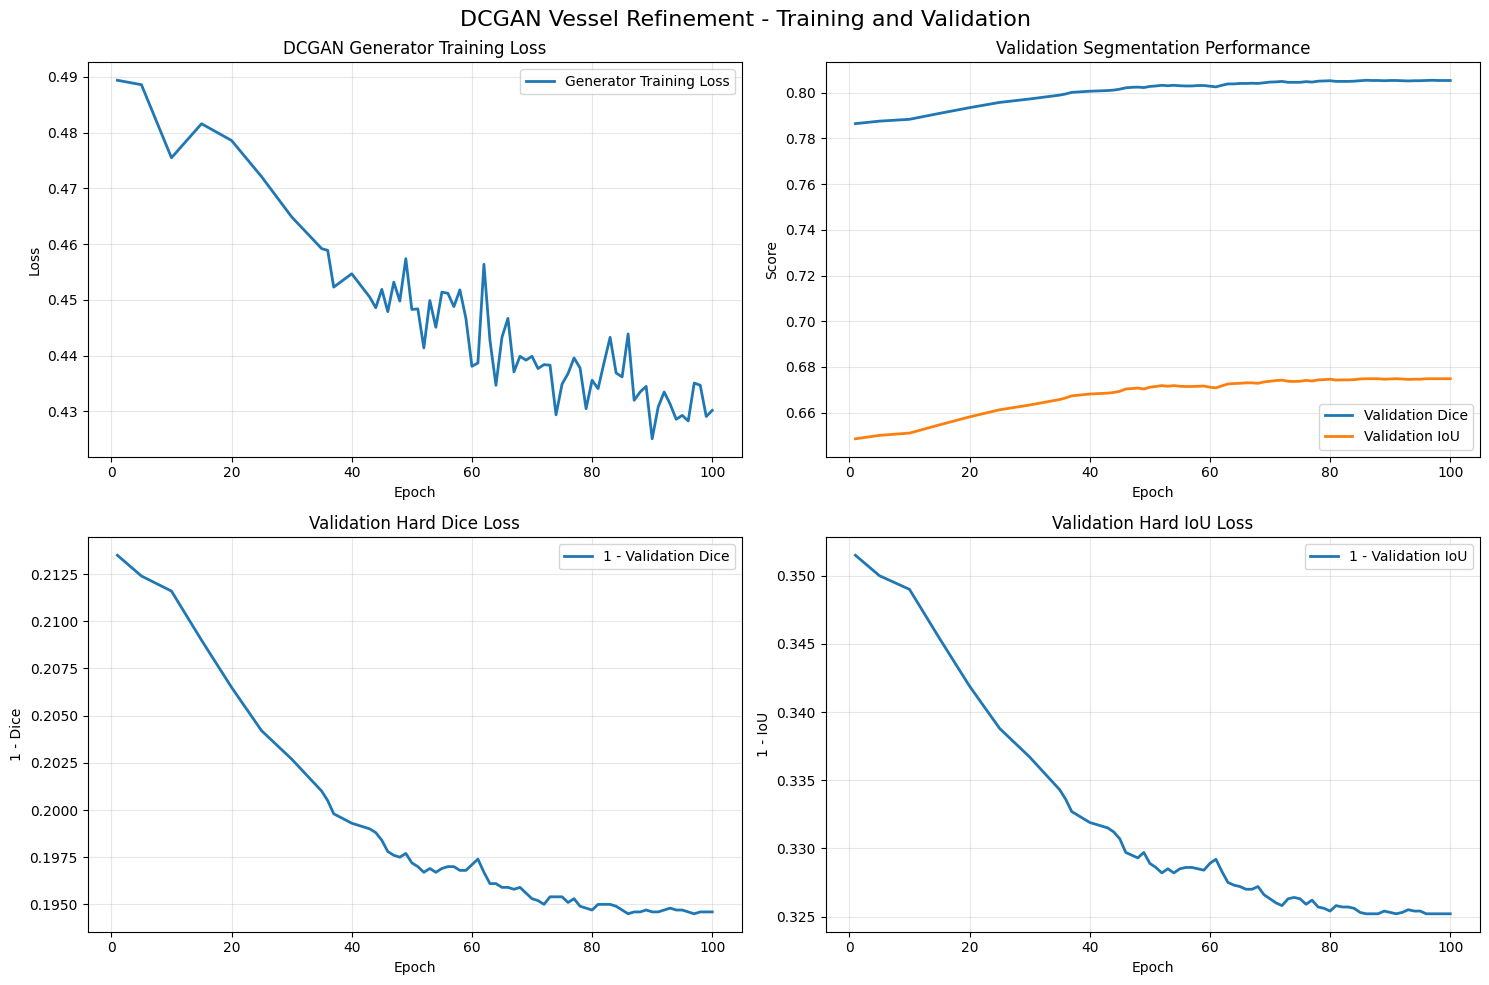

Plots saved to: /content/drive/MyDrive/DR_Project/OOF_Aligned_Paired_Vessel_GAN_V2/DCGAN_training_validation_plots.png


In [ ]:



import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Locate training history
candidates = [
    Path(OUT) / "training_history.csv",
    Path(OUT) / "DCgan_actual_printed_epoch_history.csv",
    Path("/content/DCgan_actual_printed_epoch_history.csv")
]

history_file = next(
    (p for p in candidates if p.exists()), None
)

if history_file is None:
    from google.colab import files
    uploaded = files.upload()
    history_file = Path(next(iter(uploaded)))

history = pd.read_csv(history_file)
history = history.sort_values("epoch")

epochs = history["epoch"]

# ============================================================
# CREATE FOUR PLOTS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# PLOT 1 - GENERATOR TRAINING LOSS
axes[0, 0].plot(
    epochs,
    history["train_total_generator_loss"],
    linewidth=2,
    label="Generator Training Loss"
)

axes[0, 0].set_title("DCGAN Generator Training Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)


# PLOT 2 - VALIDATION DICE AND IOU
axes[0, 1].plot(
    epochs,
    history["val_dice"],
    linewidth=2,
    label="Validation Dice"
)

axes[0, 1].plot(
    epochs,
    history["val_iou"],
    linewidth=2,
    label="Validation IoU"
)

axes[0, 1].set_title("Validation Segmentation Performance")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Score")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)


# PLOT 3 - VALIDATION DICE LOSS
axes[1, 0].plot(
    epochs,
    history["val_hard_dice_loss"],
    linewidth=2,
    label="1 - Validation Dice"
)

axes[1, 0].set_title("Validation Hard Dice Loss")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("1 - Dice")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)


# PLOT 4 - VALIDATION IOU LOSS
axes[1, 1].plot(
    epochs,
    history["val_hard_iou_loss"],
    linewidth=2,
    label="1 - Validation IoU"
)

axes[1, 1].set_title("Validation Hard IoU Loss")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("1 - IoU")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)


plt.suptitle(
    "DCGAN Vessel Refinement - Training and Validation",
    fontsize=16
)

plt.tight_layout()

save_path = Path(OUT) / "DCGAN_training_validation_plots.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Plots saved to:", save_path)


Best VALIDATION epoch: 86
Threshold selected using VALIDATION: 0.34

Exploratory TEST comparison (same 10 images and GT):
           Stage2_same_test_files  GAN_refined_same_test_files  gain_percentage_points
dice                      0.77678                      0.78908                 1.23058
iou                       0.63522                      0.65177                 1.65493
precision                 0.76729                      0.76808                 0.07881
recall                    0.78883                      0.81240                 2.35704
accuracy                  0.96199                      0.96347                 0.14774


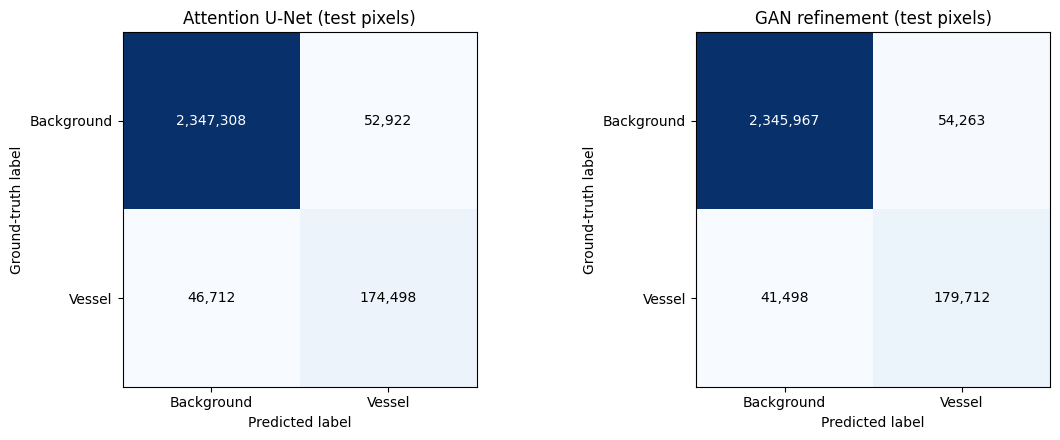


Per-image confidence and change counts:
                          image_id  mean_vessel_prediction_score  mean_image_vessel_probability  image_dice  image_iou  added_pixels  removed_pixels  total_changed_pixels
 test_DRIVE_drive_26_training_0000                        0.8673                         0.0922      0.7814     0.6412          3812             628                  4440
test_CHASEDB1_chase_Image_08L_0001                        0.8701                         0.0777      0.7695     0.6254          2129            1873                  4002
 test_DRIVE_drive_27_training_0002                        0.8838                         0.1055      0.7807     0.6402          3234             896                  4130
 test_DRIVE_drive_29_training_0003                        0.8851                         0.0820      0.7851     0.6462           976            2759                  3735
 test_DRIVE_drive_35_training_0004                        0.8774                         0.1051      0.8

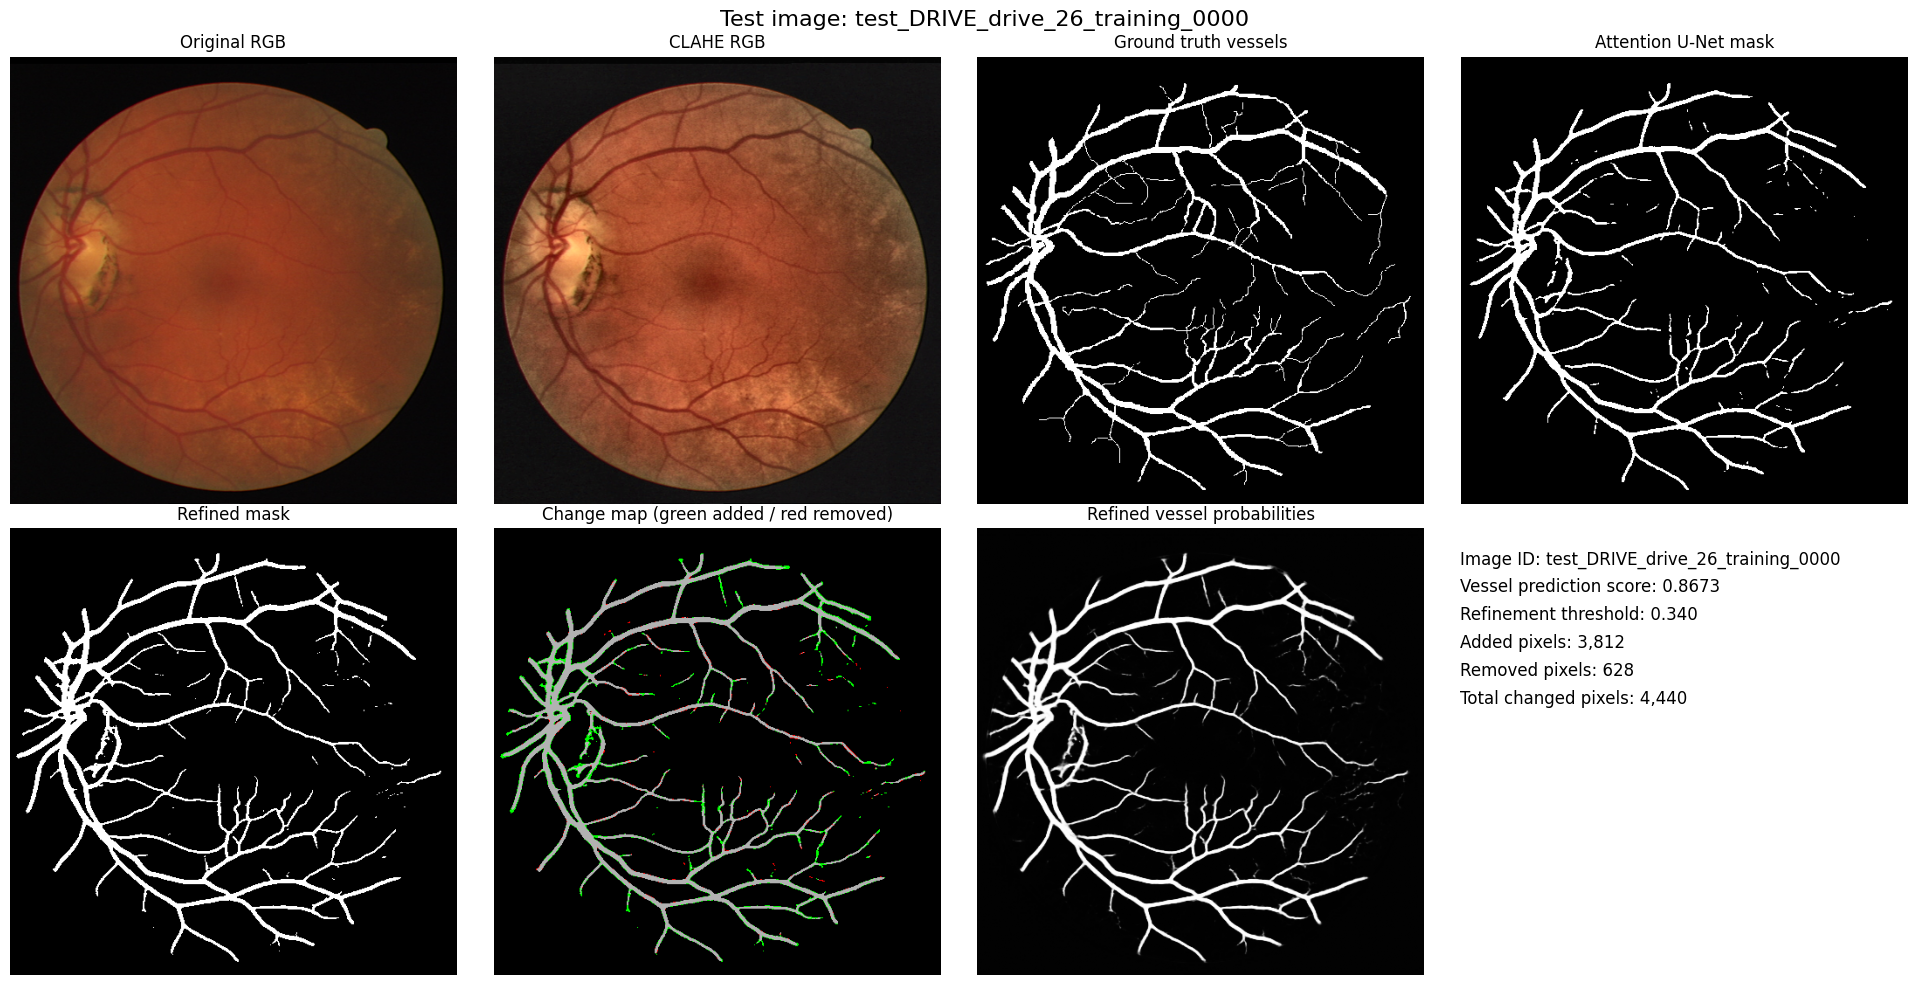

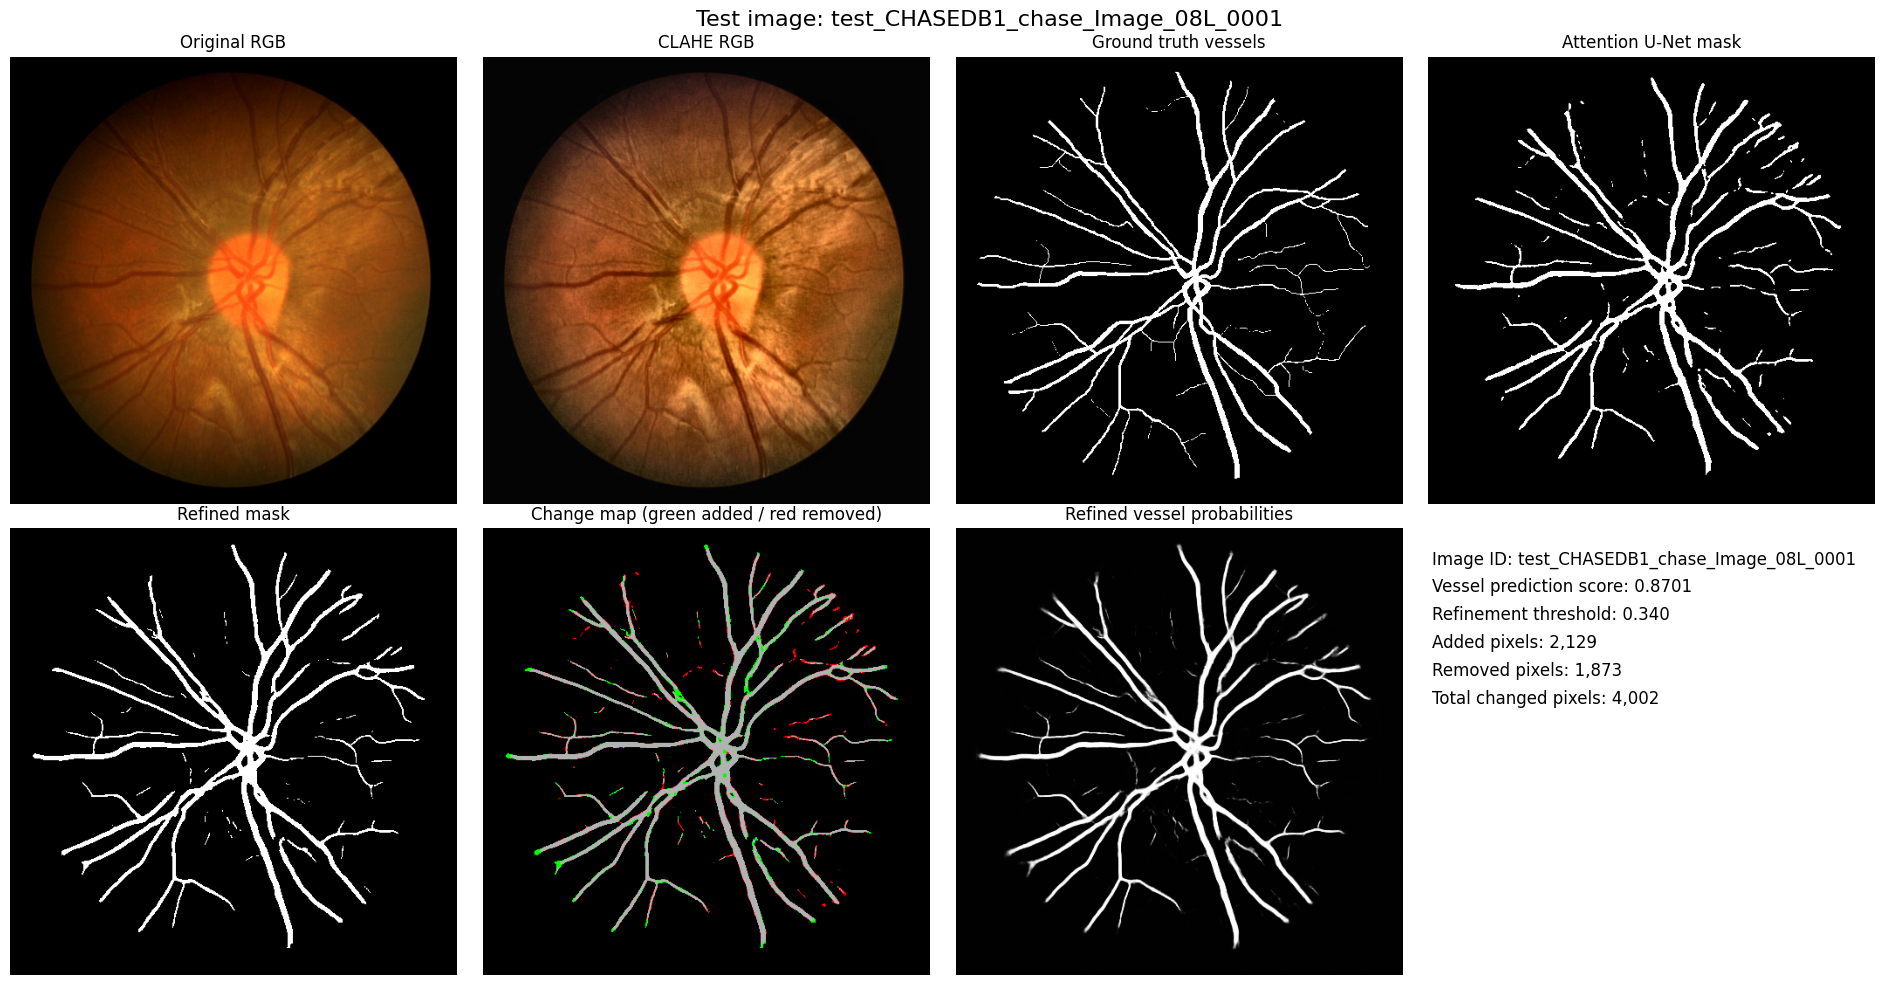


No per-epoch history CSV found. Original Cell 8 did not save validation loss.
For logged Dice/IoU history, put DCgan_actual_printed_epoch_history.csv in /content/drive/MyDrive/DR_Project/OOF_Aligned_Paired_Vessel_GAN_V2
For future full loss curves, enable Cell 8 logging before training.

Saved evaluation outputs in: /content/drive/MyDrive/DR_Project/OOF_Aligned_Paired_Vessel_GAN_V2/detailed_evaluation


In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

VIS_OUT = Path(OUT) / "detailed_evaluation"
VIS_OUT.mkdir(parents=True, exist_ok=True)
THRESHOLD_STAGE2 = 0.50

checkpoint = torch.load(Path(OUT) / "best_checkpoint.pt", map_location=DEVICE, weights_only=False)
EMA.load_state_dict(checkpoint["EMA"])
EMA.eval()
print("Best VALIDATION epoch:", checkpoint["epoch"])

@torch.inference_mode()
def get_maps(loader):
    maps = []
    for rgb, att, gt, ids in loader:
        if rgb.shape[0] != 1:
            raise ValueError("Use batch_size=1 for VAL and TEST")
        rgb_gpu, att_gpu = rgb.to(DEVICE), att.to(DEVICE)
        pred_views = []
        for dims in ((), (-1,), (-2,), (-2, -1)):
            r = torch.flip(rgb_gpu, dims) if dims else rgb_gpu
            a = torch.flip(att_gpu, dims) if dims else att_gpu
            pred = EMA(r, a).sigmoid()
            pred_views.append(torch.flip(pred, dims) if dims else pred)
        refined = torch.stack(pred_views).mean(0)[0, 0].cpu().numpy().astype(np.float32)
        img_id = str(ids[0])
        row = records.loc[records["id"] == img_id]
        if len(row) != 1:
            raise KeyError("Image ID missing or duplicated: " + img_id)
        source_rgb = row.iloc[0]["original_rgb"]
        original_rgb = np.asarray(
            Image.open(source_rgb).convert("RGB").resize((SIZE, SIZE), Image.Resampling.BILINEAR)
        )
        maps.append({
            "id": img_id,
            "original_rgb": original_rgb,
            "clahe_rgb": np.clip(rgb[0].permute(1, 2, 0).numpy(), 0, 1),
            "attention": att[0, 0].numpy().astype(np.float32),
            "refined": np.clip(refined, 0, 1),
            "gt": gt[0, 0].numpy() > 0.5,
        })
    return maps

def confusion_counts(data, name, threshold):
    tp = fp = fn = tn = 0
    per_image = []
    for item in data:
        prediction = item[name] >= threshold
        ground_truth = item["gt"]
        tpi = int(np.count_nonzero(prediction & ground_truth))
        fpi = int(np.count_nonzero(prediction & ~ground_truth))
        fni = int(np.count_nonzero(~prediction & ground_truth))
        tni = int(np.count_nonzero(~prediction & ~ground_truth))
        tp += tpi; fp += fpi; fn += fni; tn += tni
        per_image.append((tpi, fpi, fni, tni))
    return (tp, fp, fn, tn), per_image

def metrics_from_counts(data, name, threshold):
    counts, per = confusion_counts(data, name, threshold)
    tp, fp, fn, tn = counts
    dices = [2*a / max(1, 2*a+b+c) for a,b,c,d in per]
    ious = [a / max(1, a+b+c) for a,b,c,d in per]
    accs = [(a+d)/max(1,a+b+c+d) for a,b,c,d in per]
    return {
        "dice": float(np.mean(dices)),
        "iou": float(np.mean(ious)),
        "precision": tp / max(1, tp+fp),
        "recall": tp / max(1, tp+fn),
        "accuracy": float(np.mean(accs)),
    }


val_maps = get_maps(VAL)
val_base = metrics_from_counts(val_maps, "attention", THRESHOLD_STAGE2)
metric_names = ["dice", "iou", "precision", "recall", "accuracy"]
rows = []
for t in np.round(np.arange(0.20, 0.50001, 0.005), 3):
    rows.append({"threshold": t, **metrics_from_counts(val_maps, "refined", float(t))})
val_sweep = pd.DataFrame(rows)
val_sweep.to_csv(VIS_OUT / "validation_threshold_sweep.csv", index=False)
eligible = val_sweep.copy()
for metric_name in metric_names:
    eligible = eligible[eligible[metric_name] > val_base[metric_name]]
if len(eligible):
    selected = eligible.sort_values(["recall", "dice"], ascending=False).iloc[0]
    selected_threshold = float(selected["threshold"])
    print("Threshold selected using VALIDATION:", selected_threshold)
else:
    selected_threshold = 0.50
    print("No validation threshold improved all five measures. Using 0.50 for diagnosis.")


test_maps = get_maps(TEST)
base = metrics_from_counts(test_maps, "attention", THRESHOLD_STAGE2)
ref = metrics_from_counts(test_maps, "refined", selected_threshold)
comparison = pd.DataFrame({
    "Stage2_same_test_files": base,
    "GAN_refined_same_test_files": ref,
    "gain_percentage_points": {k: (ref[k]-base[k])*100 for k in metric_names},
})
comparison.to_csv(VIS_OUT / "test_metric_comparison.csv")
print("\nExploratory TEST comparison (same 10 images and GT):")
print(comparison.round(5).to_string())

# Confusion matrix: rows = true background/vessel; columns = predicted background/vessel.
base_counts, _ = confusion_counts(test_maps, "attention", THRESHOLD_STAGE2)
ref_counts, _ = confusion_counts(test_maps, "refined", selected_threshold)
def show_confusion(counts, title, ax):
    tp, fp, fn, tn = counts
    cm = np.array([[tn, fp], [fn, tp]], dtype=np.int64)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0,1], ["Background", "Vessel"])
    ax.set_yticks([0,1], ["Background", "Vessel"])
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Ground-truth label")
    ax.set_title(title)
    cutoff = cm.max() * 0.45
    for r in range(2):
        for c in range(2):
            ax.text(c, r, f"{cm[r,c]:,}", ha="center", va="center",
                    color="white" if cm[r,c]>cutoff else "black", fontsize=10)
    return cm
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cm_a = show_confusion(base_counts, "Attention U-Net (test pixels)", axes[0])
cm_b = show_confusion(ref_counts, "GAN refinement (test pixels)", axes[1])
fig.tight_layout()
fig.savefig(VIS_OUT / "test_confusion_matrices.png", dpi=160)
plt.show()
pd.DataFrame(cm_b, index=["true_background","true_vessel"],
             columns=["pred_background","pred_vessel"]).to_csv(VIS_OUT / "refined_confusion_matrix.csv")

# Save all test probability maps, binary masks, and image-level statistics.
summary = []
for item in test_maps:
    old = item["attention"] >= THRESHOLD_STAGE2
    new = item["refined"] >= selected_threshold
    added = new & ~old
    removed = old & ~new
    tp = int(np.count_nonzero(new & item["gt"]))
    fp = int(np.count_nonzero(new & ~item["gt"]))
    fn = int(np.count_nonzero(~new & item["gt"]))

    confidence = float(item["refined"][new].mean()) if new.any() else 0.0
    summary.append({
        "image_id":item["id"],
        "mean_vessel_prediction_score":confidence,
        "mean_image_vessel_probability":float(item["refined"].mean()),
        "image_dice":2*tp/max(1,2*tp+fp+fn),
        "image_iou":tp/max(1,tp+fp+fn),
        "added_pixels":int(added.sum()),
        "removed_pixels":int(removed.sum()),
        "total_changed_pixels":int((added|removed).sum()),
    })
    np.save(VIS_OUT / f"{item['id']}_probability.npy", item["refined"])
    Image.fromarray((new.astype(np.uint8)*255)).save(VIS_OUT / f"{item['id']}_refined.png")
summary_df = pd.DataFrame(summary)
summary_df.to_csv(VIS_OUT / "test_image_prediction_scores_and_changes.csv", index=False)
print("\nPer-image confidence and change counts:")
print(summary_df.round(4).to_string(index=False))


def show_test_image(item, display=True):
    old = item["attention"] >= THRESHOLD_STAGE2
    new = item["refined"] >= selected_threshold
    added = new & ~old
    removed = old & ~new
    change = np.zeros((*old.shape, 3), np.float32)
    change[old & new] = [0.7, 0.7, 0.7]
    change[added] = [0, 1, 0]
    change[removed] = [1, 0, 0]
    vessel_score = float(item["refined"][new].mean()) if new.any() else 0.0
    panels = [item["original_rgb"],item["clahe_rgb"],item["gt"],
              old,new,change,item["refined"]]
    titles = ["Original RGB", "CLAHE RGB", "Ground truth vessels",
              "Attention U-Net mask", "Refined mask",
              "Change map (green added / red removed)", "Refined vessel probabilities"]
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    for ax, img, title in zip(axes.flat[:7], panels, titles):
        ax.imshow(img, cmap="gray" if img.ndim == 2 else None, vmin=0, vmax=1)
        ax.set_title(title)
        ax.axis("off")
    axes.flat[7].axis("off")
    info = (f"Image ID: {item['id']}\n"
            f"Vessel prediction score: {vessel_score:.4f}\n"
            f"Refinement threshold: {selected_threshold:.3f}\n"
            f"Added pixels: {added.sum():,}\n"
            f"Removed pixels: {removed.sum():,}\n"
            f"Total changed pixels: {(added|removed).sum():,}")
    axes.flat[7].text(0.02, 0.95, info, va="top", fontsize=12, linespacing=1.7)
    fig.suptitle(f"Test image: {item['id']}", fontsize=16)
    fig.tight_layout()
    fig.savefig(VIS_OUT / f"{item['id']}_seven_views.png", dpi=140)
    if display:
        plt.show()
    else:
        plt.close(fig)

# Show two examples
for index, item in enumerate(test_maps):
    show_test_image(item, display=(index < 2))

# Display genuine training/loss histories when available.
# The existing 100-epoch run did not record a validation total-loss curve.
hist_path = Path(OUT) / "training_history.csv"
printed_log_candidates = [
    Path(OUT) / "DCgan_actual_printed_epoch_history.csv",
    Path("/content/DCgan_actual_printed_epoch_history.csv"),
]
if hist_path.is_file():
    hist = pd.read_csv(hist_path)
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    for ax, column, title in [
        (axes[0,0], "train_seg_loss", "Training segmentation loss"),
        (axes[0,1], "val_seg_loss", "Validation segmentation loss"),
        (axes[1,0], "val_dice_loss", "Validation soft Dice loss"),
        (axes[1,1], "val_iou_loss", "Validation soft IoU loss"),
    ]:
        if column in hist.columns and hist[column].notna().any():
            ax.plot(hist["epoch"], hist[column], marker=".", markersize=2)
            ax.set_xlabel("Epoch")
            ax.set_ylabel("Loss")
            ax.set_title(title)
            ax.grid(alpha=.25)
        else:
            ax.text(.5,.5,f"{title}\nwas not logged",ha="center",va="center")
            ax.axis("off")
    fig.tight_layout()
    fig.savefig(VIS_OUT / "training_loss_curves.png", dpi=160)
    plt.show()
else:
    found_log = next((p for p in printed_log_candidates if p.is_file()), None)
    if found_log is not None:
        hist = pd.read_csv(found_log)
        fig, axes = plt.subplots(2, 2, figsize=(13, 8))
        for ax, col, title in [
            (axes[0,0], "train_total_generator_loss", "Logged generator training loss"),
            (axes[1,0], "val_hard_dice_loss", "1 - validation Dice (not soft loss)"),
            (axes[1,1], "val_hard_iou_loss", "1 - validation IoU (not soft loss)"),
        ]:
            ax.plot(hist["epoch"], hist[col], marker=".", markersize=2)
            ax.set_xlabel("Printed epoch")
            ax.set_ylabel("Logged/derived value")
            ax.set_title(title)
            ax.grid(alpha=.25)
        axes[0,1].text(.5,.5,"Validation total loss was\nnot logged in this run",ha="center",va="center")
        axes[0,1].axis("off")
        fig.tight_layout()
        fig.savefig(VIS_OUT / "available_logged_loss_curves.png", dpi=160)
        plt.show()
    else:
        print("\nNo per-epoch history CSV found. Original Cell 8 did not save validation loss.")
        print("For logged Dice/IoU history, put DCgan_actual_printed_epoch_history.csv in", OUT)
        print("For future full loss curves, enable Cell 8 logging before training.")

print("\nSaved evaluation outputs in:", VIS_OUT)


STAGE 2 vs DCGAN REFINEMENT: same images 27, 29, 35


,27,29,35
Image ID,,,
Stage2 Prediction Score,0.9077,0.9114,0.9062
Refined Prediction Score,0.8838,0.8851,0.8774
Stage2 Dice,0.7774,0.7727,0.7992
Refined Dice,0.7807,0.7851,0.8042
Stage2 IoU,0.6359,0.6296,0.6655
Refined IoU,0.6402,0.6462,0.6725
Stage2 pixels,24698,22860,25310
Refined pixels,27036,21077,27133
Added pixels,3234,976,3060


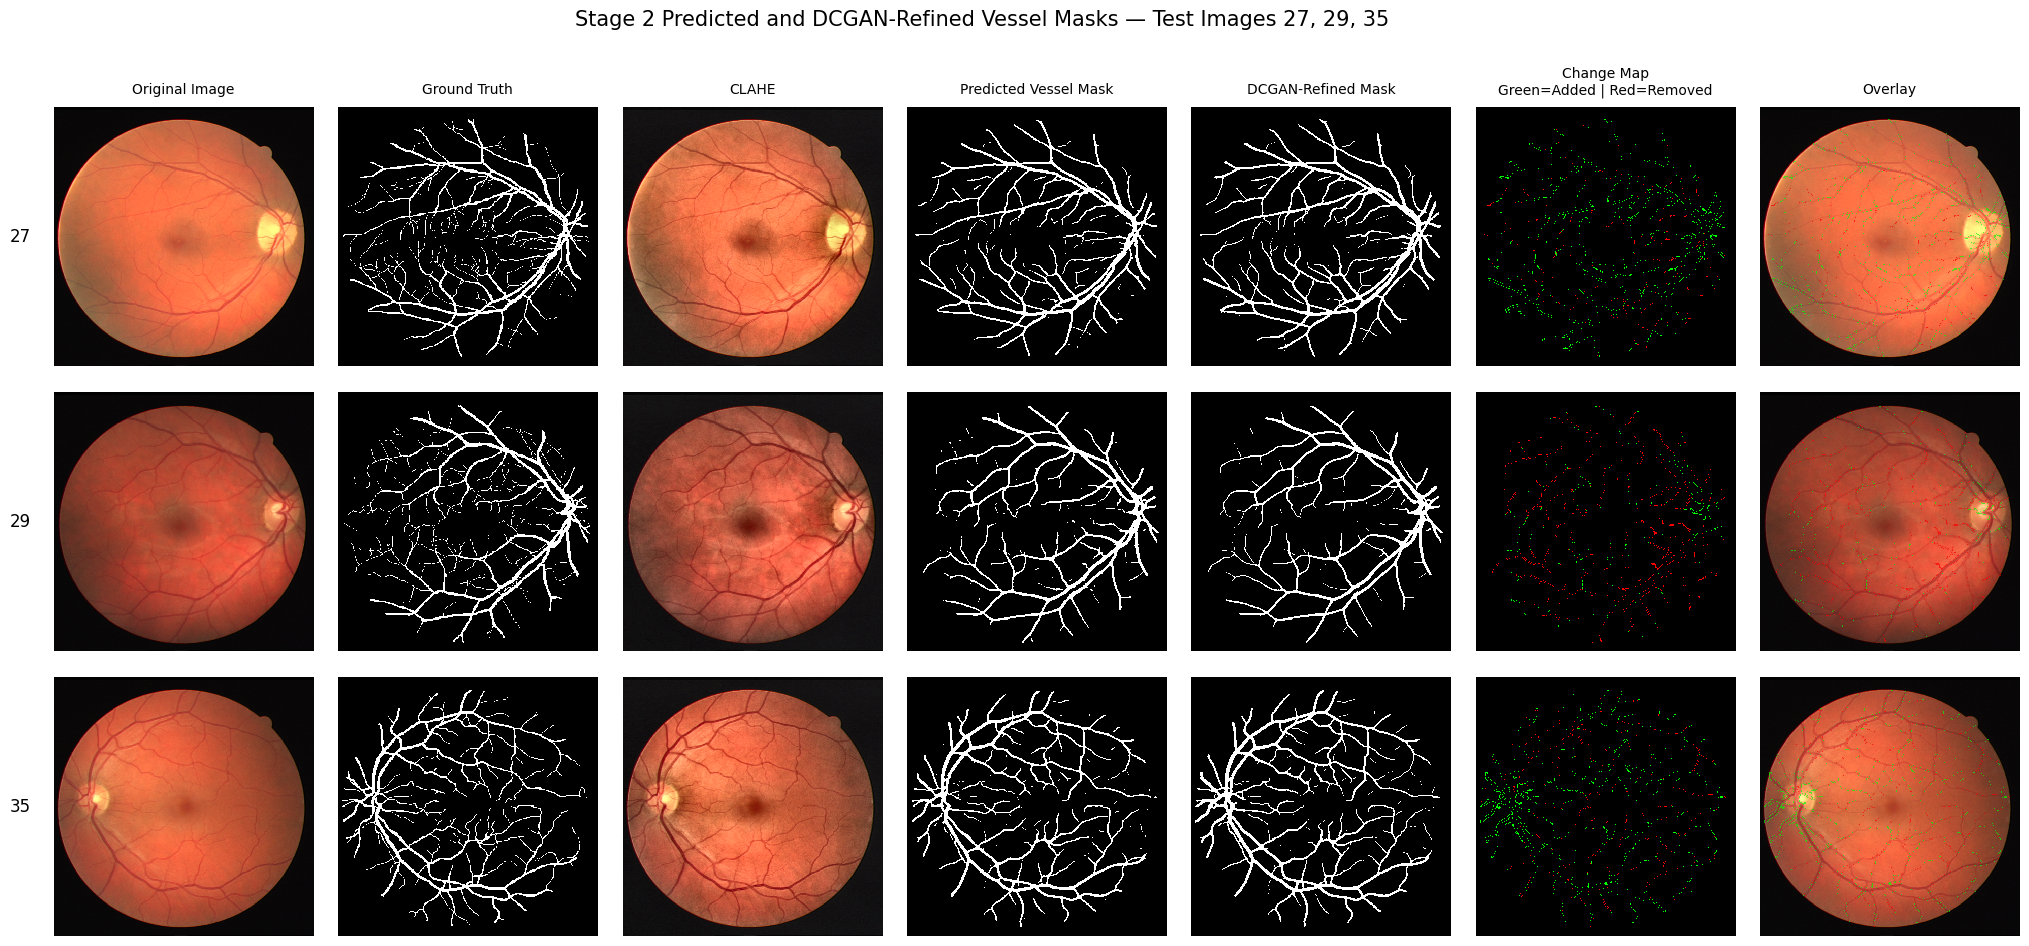


Saved table: /content/drive/MyDrive/DR_Project/OOF_Aligned_Paired_Vessel_GAN_V2/detailed_evaluation/DCGAN_comparison_images_27_29_35.csv
Saved 3-image comparison figure: /content/drive/MyDrive/DR_Project/OOF_Aligned_Paired_Vessel_GAN_V2/detailed_evaluation/DCGAN_Images_27_29_35_Comparison.png
Image 27: added=3234, removed=896, changed=4130
Image 29: added=976, removed=2759, changed=3735
Image 35: added=3060, removed=1237, changed=4297


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

if 'test_maps' not in globals() or not test_maps:
    raise RuntimeError('Run Cell 11 (detailed evaluation) first to create test_maps.')
if 'selected_threshold' not in globals():
    raise RuntimeError('Run Cell 11 first to select the DCGAN threshold using validation data.')
if 'THRESHOLD_STAGE2' not in globals():
    raise RuntimeError('Run Cell 11 first to define THRESHOLD_STAGE2.')

stage2_threshold = float(THRESHOLD_STAGE2)
refined_threshold = float(selected_threshold)
save_dir = Path(VIS_OUT)
save_dir.mkdir(parents=True, exist_ok=True)


chosen = {}
for image_number in (27, 29, 35):
    tag = f'_drive_{image_number}_training_'
    matches = [m for m in test_maps if tag in str(m['id'])]
    if len(matches) != 1:
        raise ValueError(
            f'Image {image_number}: expected one match, found {len(matches)}. '
            f'Available IDs: {[m["id"] for m in test_maps]}'
        )
    chosen[str(image_number)] = matches[0]


def dice_iou(predicted, ground_truth):
    tp = int(np.count_nonzero(predicted & ground_truth))
    fp = int(np.count_nonzero(predicted & ~ground_truth))
    fn = int(np.count_nonzero(~predicted & ground_truth))
    return (2 * tp / max(1, 2 * tp + fp + fn),
            tp / max(1, tp + fp + fn))


def vessel_score(probabilities, binary_mask):
    # Mean vessel-pixel probability, NOT a DR severity prediction score.
    return float(probabilities[binary_mask].mean()) if binary_mask.any() else 0.0


def rgb_float(image):
    image = np.asarray(image)
    if image.ndim != 3 or image.shape[2] != 3:
        raise ValueError(f'Expected RGB image (H,W,3), got {image.shape}')
    image = image.astype(np.float32)
    if image.max() > 1.0:
        image = image / 255.0
    return np.clip(image, 0, 1)


results = {}
figure_rows = []
for image_number, item in chosen.items():

    attention_probs = np.asarray(item['attention'], dtype=np.float32)
    dcgan_probs = np.asarray(item['refined'], dtype=np.float32)
    ground_truth = np.asarray(item['gt'], dtype=bool)
    if not (attention_probs.shape == dcgan_probs.shape == ground_truth.shape):
        raise ValueError(f'Mask sizes do not match for image {image_number}')

    stage2_mask = attention_probs >= stage2_threshold
    dcgan_mask = dcgan_probs >= refined_threshold


    # green = DCGAN has a vessel where Stage 2 did not;
    # red   = Stage 2 had a vessel that DCGAN removed.
    added = dcgan_mask & ~stage2_mask
    removed = stage2_mask & ~dcgan_mask
    unchanged = stage2_mask & dcgan_mask

    stage2_dice, stage2_iou = dice_iou(stage2_mask, ground_truth)
    refined_dice, refined_iou = dice_iou(dcgan_mask, ground_truth)
    results[image_number] = {
        'Stage2 Prediction Score': vessel_score(attention_probs, stage2_mask),
        'Refined Prediction Score': vessel_score(dcgan_probs, dcgan_mask),
        'Stage2 Dice': stage2_dice,
        'Refined Dice': refined_dice,
        'Stage2 IoU': stage2_iou,
        'Refined IoU': refined_iou,
        'Stage2 pixels': int(stage2_mask.sum()),
        'Refined pixels': int(dcgan_mask.sum()),
        'Added pixels': int(added.sum()),
        'Removed pixels': int(removed.sum()),
        'Changed pixels': int((added | removed).sum()),
    }

    original = rgb_float(item['original_rgb'])
    clahe = rgb_float(item['clahe_rgb'])

    # Black background; show ONLY actual changes, as in your cGAN figure.
    # Same red/green meanings as the existing Cell 11 DCGAN change map.
    change_map = np.zeros((*stage2_mask.shape, 3), dtype=np.float32)
    change_map[added] = (0.0, 1.0, 0.0)    # Green: added
    change_map[removed] = (1.0, 0.0, 0.0)  # Red: removed
    # Optional to reproduce Cell 11's gray unchanged-vessel pixels:
    # change_map[unchanged] = (0.7, 0.7, 0.7)

    # Overlay exactly the SAME green/red changes on the original RGB.
    overlay = original.copy()
    alpha = 0.65
    overlay[added] = (1 - alpha) * overlay[added] + alpha * np.array([0., 1., 0.])
    overlay[removed] = (1 - alpha) * overlay[removed] + alpha * np.array([1., 0., 0.])

    figure_rows.append({
        'id': image_number,
        'panels': [original, ground_truth, clahe, stage2_mask,
                   dcgan_mask, change_map, overlay],
        'counts': (int(added.sum()), int(removed.sum()), int((added | removed).sum()))
    })


table = pd.DataFrame(results)
table.index.name = 'Image ID'
formatted = table.copy().astype(object)
for metric in formatted.index:
    formatted.loc[metric] = [
        f'{float(x):.4f}' if metric.endswith(('Score', 'Dice', 'IoU')) else f'{int(x)}'
        for x in table.loc[metric]
    ]
print('STAGE 2 vs DCGAN REFINEMENT: same images 27, 29, 35')

display(formatted)
csv_file = save_dir / 'DCGAN_comparison_images_27_29_35.csv'
formatted.to_csv(csv_file)


panel_titles = [
    'Original Image', 'Ground Truth', 'CLAHE',
    'Predicted Vessel Mask', 'DCGAN-Refined Mask',
    'Change Map\nGreen=Added | Red=Removed', 'Overlay'
]
fig, axes = plt.subplots(3, 7, figsize=(21, 9.7), facecolor='white')
for row_idx, data in enumerate(figure_rows):
    for col_idx, (panel, title) in enumerate(zip(data['panels'], panel_titles)):
        ax = axes[row_idx, col_idx]
        if np.asarray(panel).ndim == 2:
            ax.imshow(panel, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        else:
            ax.imshow(panel, vmin=0, vmax=1, interpolation='nearest')
        if row_idx == 0:
            ax.set_title(title, fontsize=10, pad=9)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    axes[row_idx, 0].set_ylabel(data['id'], rotation=0,
                                fontsize=12, labelpad=24, va='center')

fig.suptitle('Stage 2 Predicted and DCGAN-Refined Vessel Masks — Test Images 27, 29, 35',
             fontsize=15, y=0.99)
fig.subplots_adjust(left=0.055, right=0.997, top=0.89, bottom=0.035,
                    wspace=0.045, hspace=0.10)
figure_file = save_dir / 'DCGAN_Images_27_29_35_Comparison.png'
fig.savefig(figure_file, dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)

print('\nSaved table:', csv_file)
print('Saved 3-image comparison figure:', figure_file)
for row in figure_rows:
    a, r, c = row['counts']
    print(f"Image {row['id']}: added={a}, removed={r}, changed={c}")


In [ ]:
from google.colab import drive, files
from pathlib import Path
import os, re, zipfile, shutil, gc
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

drive.mount('/content/drive')
DRIVE_HOME = Path('/content/drive/MyDrive')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SIZE = 512
BATCH = 2           # decrease to 1 for low GPU memory
FOUR_VIEW_TTA = True  # matches validation/test inference in DCgan.ipynb
SAVE_PROB_NPY = False # True uses much more storage for large DR2015
COPY_RGB_TO_LOCAL = True  # copy paired DR2015 RGB images locally for faster input

# Use a ZIP on Google Drive by setting a path, or keep None for browser upload.
DR2015_STAGE2_ZIP = None

# Original DR2015 RGB images from your Stage 3 Part 1 notebook.
DR_IMAGE_ROOT = DRIVE_HOME / 'Dataset_extracted' / 'colored_images' / 'colored_images'

# Actual trained DCGAN and optional original Stage 2 model weights.
GAN_CHECKPOINT = DRIVE_HOME / 'DR_Project' / 'OOF_Aligned_Paired_Vessel_GAN_V2' / 'best_checkpoint.pt'
STAGE2_WEIGHTS = DRIVE_HOME / 'DR_Project' / 'stage2' / 'weights' / 'stage2_attunet_best.pth'

# Outputs stored safely in a SEPARATE folder (original Stage 2 masks are not overwritten).
# Save all refinement outputs locally in Colab
EXPORT_DIR = Path("/content/DR2015_DCGAN_Refined")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Local output folder:", EXPORT_DIR)

# If the ZIP supplies .npy maps, those are used. Otherwise prefer regenerating
# Stage 2 probability maps from the RGB and its checkpoint, rather than using
# 0/1 binary masks as inputs to a model trained on continuous probabilities.
REGENERATE_STAGE2_PROB_IF_PNG_ONLY = True
ALLOW_BINARY_FALLBACK = True  # warn clearly if Stage 2 checkpoint absent

# Use threshold chosen on the original vessel validation split if one exists.
CALIBRATED_THRESHOLD = GAN_CHECKPOINT.parent / 'recall_calibrated' / 'selected_threshold.txt'
print('Device:', DEVICE)
print('GAN checkpoint:', GAN_CHECKPOINT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
GAN checkpoint: /content/drive/MyDrive/DR_Project/OOF_Aligned_Paired_Vessel_GAN_V2/best_checkpoint.pt


In [ ]:
def stage2_rgb(path):
    a=np.asarray(Image.open(path).convert('RGB'))
    lab=cv2.cvtColor(a,cv2.COLOR_RGB2LAB)
    l,aa,bb=cv2.split(lab)
    l=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8)).apply(l)
    rgb=cv2.cvtColor(cv2.merge([l,aa,bb]),cv2.COLOR_LAB2RGB)
    # Match Stage 2 exactly: apply CLAHE at original resolution, then PIL bilinear resize.
    rgb=np.asarray(Image.fromarray(rgb).resize((SIZE,SIZE),Image.Resampling.BILINEAR))
    return torch.from_numpy(np.ascontiguousarray(rgb.transpose(2,0,1))).float()/255.0

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.net(x)

class AttentionGate(nn.Module):

    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(F_g, F_int, 1), nn.BatchNorm2d(F_int))
        self.W_x = nn.Sequential(nn.Conv2d(F_l, F_int, 1), nn.BatchNorm2d(F_int))
        self.psi = nn.Sequential(nn.Conv2d(F_int, 1, 1), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class AttUNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=64):
        super().__init__()
        # Encoder
        self.enc1 = DoubleConv(in_ch, base)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(base, base*2)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = DoubleConv(base*2, base*4)
        self.pool3 = nn.MaxPool2d(2)
        self.enc4 = DoubleConv(base*4, base*8)
        self.pool4 = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(base*8, base*16)

        # Decoder
        self.up4 = nn.ConvTranspose2d(base*16, base*8, 2, stride=2)
        self.att4 = AttentionGate(base*8, base*8, base*4)
        self.dec4 = DoubleConv(base*16, base*8)

        self.up3 = nn.ConvTranspose2d(base*8, base*4, 2, stride=2)
        self.att3 = AttentionGate(base*4, base*4, base*2)
        self.dec3 = DoubleConv(base*8, base*4)

        self.up2 = nn.ConvTranspose2d(base*4, base*2, 2, stride=2)
        self.att2 = AttentionGate(base*2, base*2, base)
        self.dec2 = DoubleConv(base*4, base*2)

        self.up1 = nn.ConvTranspose2d(base*2, base, 2, stride=2)
        self.att1 = AttentionGate(base, base, base//2)
        self.dec1 = DoubleConv(base*2, base)

        self.out = nn.Conv2d(base, out_ch, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))

        b = self.bottleneck(self.pool4(e4))

        d4 = self.up4(b)
        e4a = self.att4(d4, e4)
        d4 = self.dec4(torch.cat([d4, e4a], dim=1))

        d3 = self.up3(d4)
        e3a = self.att3(d3, e3)
        d3 = self.dec3(torch.cat([d3, e3a], dim=1))

        d2 = self.up2(d3)
        e2a = self.att2(d2, e2)
        d2 = self.dec2(torch.cat([d2, e2a], dim=1))

        d1 = self.up1(d2)
        e1a = self.att1(d1, e1)
        d1 = self.dec1(torch.cat([d1, e1a], dim=1))

        return self.out(d1)

class Res(nn.Module):
    def __init__(self,cin,cout):
        super().__init__()
        self.main=nn.Sequential(nn.Conv2d(cin,cout,3,padding=1,bias=False),
           nn.GroupNorm(8,cout),nn.SiLU(inplace=True),
           nn.Conv2d(cout,cout,3,padding=1,bias=False),nn.GroupNorm(8,cout))
        self.skip=nn.Conv2d(cin,cout,1) if cin!=cout else nn.Identity()
    def forward(self,x):return F.silu(self.main(x)+self.skip(x))

class Up(nn.Module):
    def __init__(self,cin,skip,cout):
        super().__init__()
        self.proj=nn.Conv2d(cin,cout,1)
        self.conv=Res(cout+skip,cout)
    def forward(self,x,s):
        x=F.interpolate(x,size=s.shape[-2:],mode='bilinear',align_corners=False)
        return self.conv(torch.cat([self.proj(x),s],dim=1))

class VesselCorrectionG(nn.Module):


    def __init__(self,w=24):
        super().__init__()
        self.stem=Res(5,w)
        self.e1=Res(w,w*2)
        self.e2=Res(w*2,w*4)
        self.e3=Res(w*4,w*6)
        self.mid=Res(w*6,w*6)
        self.d2=Up(w*6,w*4,w*4)
        self.d1=Up(w*4,w*2,w*2)
        self.d0=Up(w*2,w,w)
        self.add=nn.Conv2d(w,1,1)
        self.remove=nn.Conv2d(w,1,1)
        nn.init.constant_(self.add.bias,-1.2)
        nn.init.constant_(self.remove.bias,-1.2)
    def forward(self,rgb,att,extra=False):
        green=rgb[:,1:2]
        dark=(F.max_pool2d(green,9,1,4)-green).clamp(0,1)
        a=self.stem(torch.cat([rgb,att,dark],dim=1))
        b=self.e1(F.avg_pool2d(a,2))
        c=self.e2(F.avg_pool2d(b,2))
        d=self.e3(F.avg_pool2d(c,2))
        h=self.d0(self.d1(self.d2(self.mid(d),c),b),a)
        a_logits=self.add(h);r_logits=self.remove(h)
        base=torch.logit(att.clamp(.01,.99))
        logits=base+6.0*(torch.sigmoid(a_logits)-torch.sigmoid(r_logits))
        return (logits,a_logits,r_logits) if extra else logits
print('Model classes and Stage 2 CLAHE preprocessing are ready.')


Model classes and Stage 2 CLAHE preprocessing are ready.


In [ ]:


from pathlib import Path

# Existing extracted dataset in Google Drive
RGB_EXTRACT = Path(
    "/content/drive/MyDrive/Dataset"
)

# Original RGB image folder
DR_IMAGE_ROOT = (
    RGB_EXTRACT / "colored_images" / "colored_images"
)

# Automatically locate the correct folder if nested differently
if not DR_IMAGE_ROOT.is_dir():

    candidates = [
        p for p in RGB_EXTRACT.rglob("colored_images")
        if p.is_dir()
    ]

    class_names = {
        "no_dr", "mild", "moderate",
        "severe", "proliferate_dr", "proliferative_dr"
    }

    for candidate in candidates:

        children = {
            p.name.lower()
            for p in candidate.iterdir()
            if p.is_dir()
        }

        if children & class_names:
            DR_IMAGE_ROOT = candidate
            break

if not DR_IMAGE_ROOT.is_dir():
    raise FileNotFoundError(
        f"DR2015 RGB folder not found inside {RGB_EXTRACT}"
    )

# Count RGB images
extensions = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}

rgb_images = [
    p for p in DR_IMAGE_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

if not rgb_images:
    raise RuntimeError(
        f"No RGB images found in {DR_IMAGE_ROOT}"
    )

# Enable copying matched RGB images to local Colab storage
COPY_RGB_TO_LOCAL = True

# Reuse the previously uploaded Stage 2 mask ZIP
DR2015_STAGE2_ZIP = (
    EXPORT_DIR / "original_input_zip" / "stage2_masks.zip"
)

print("RGB dataset loaded successfully.")
print("RGB folder:", DR_IMAGE_ROOT)
print("Total RGB images:", len(rgb_images))
print("Copy RGB locally:", COPY_RGB_TO_LOCAL)
print("Stage 2 ZIP:", DR2015_STAGE2_ZIP)


RGB dataset loaded successfully.
RGB folder: /content/drive/MyDrive/Dataset/colored_images/colored_images
Total RGB images: 35126
Copy RGB locally: True
Stage 2 ZIP: /content/drive/MyDrive/DR_Project/DR2015_DCGAN_Refined/original_input_zip/stage2_masks.zip


In [ ]:

# ============================================================
# CELL 2B - FAST COPY DR2015 RGB FOLDER FROM DRIVE TO COLAB
# NO RGB ZIP REQUIRED
# ============================================================

import shutil
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm

# ============================================================
# 1. SOURCE - EXISTING GOOGLE DRIVE DATASET
# ============================================================

RGB_DRIVE_ROOT = Path(
    "/content/drive/MyDrive/Dataset/colored_images/colored_images"
)

# Destination - Colab local storage
LOCAL_RGB_ROOT = Path("/content/dr2015_rgb_copy")

# Existing Attention U-Net predicted-mask ZIP
MASK_ZIP_DRIVE = Path(
    "/content/drive/MyDrive/DR_Project/"
    "DR2015_DCGAN_Refined/original_input_zip/stage2_masks.zip"
)

LOCAL_MASK_ZIP = Path("/content/stage2_masks.zip")

# Local output folder for DCGAN refinement
EXPORT_DIR = Path("/content/DR2015_DCGAN_Refined")

LOCAL_RGB_ROOT.mkdir(parents=True, exist_ok=True)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

if not RGB_DRIVE_ROOT.is_dir():
    raise FileNotFoundError(RGB_DRIVE_ROOT)

# ============================================================
# 2. FIND ORIGINAL RGB IMAGES
# ============================================================

IMG_EXTS = {
    ".jpg", ".jpeg", ".png",
    ".tif", ".tiff", ".bmp"
}

print("Finding RGB images in Google Drive...")

source_files = [
    p for p in RGB_DRIVE_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in IMG_EXTS
]

print("Total RGB images found:", len(source_files))

if not source_files:
    raise RuntimeError("No RGB images found.")

# ============================================================
# 3. FAST PARALLEL COPY WITH PROGRESS BAR
# ============================================================

def copy_image(src):

    relative_path = src.relative_to(RGB_DRIVE_ROOT)

    dst = LOCAL_RGB_ROOT / relative_path

    dst.parent.mkdir(parents=True, exist_ok=True)

    # Skip correctly sized files already copied
    if dst.exists():
        if dst.stat().st_size == src.stat().st_size:
            return "skipped"

    # Use faster copyfile instead of copy2
    temp = dst.with_name(dst.name + ".part")

    shutil.copyfile(src, temp)

    if temp.stat().st_size != src.stat().st_size:
        raise IOError(f"Incomplete copy: {src}")

    temp.replace(dst)

    return "copied"


copied = 0
skipped = 0

print("\nCopying RGB images with 8 parallel workers...")

with ThreadPoolExecutor(max_workers=8) as executor:

    futures = [
        executor.submit(copy_image, src)
        for src in source_files
    ]

    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Copying DR2015 RGB",
        unit="image"
    ):

        result = future.result()

        if result == "copied":
            copied += 1
        else:
            skipped += 1

print("\nRGB dataset copying completed.")
print("New images copied:", copied)
print("Previously copied:", skipped)

# ============================================================
# 4. COPY STAGE 2 MASK ZIP LOCALLY
# ============================================================

if not MASK_ZIP_DRIVE.is_file():
    raise FileNotFoundError(MASK_ZIP_DRIVE)

if (
    not LOCAL_MASK_ZIP.exists()
    or LOCAL_MASK_ZIP.stat().st_size
       != MASK_ZIP_DRIVE.stat().st_size
):

    print("\nCopying Stage 2 mask ZIP...")

    shutil.copyfile(MASK_ZIP_DRIVE, LOCAL_MASK_ZIP)

    print("Mask ZIP copied locally.")

else:

    print("Stage 2 mask ZIP already copied.")

# ============================================================
# 5. SET LOCAL PATHS FOR CELL 3
# ============================================================

DR_IMAGE_ROOT = LOCAL_RGB_ROOT
DR2015_STAGE2_ZIP = LOCAL_MASK_ZIP
COPY_RGB_TO_LOCAL = False

# ============================================================
# 6. FINAL SUMMARY
# ============================================================

print("\n========================================")
print("DR2015 LOCAL DATASET READY")
print("========================================")

print("Total RGB images:", len(source_files))

print("\nRGB dataset:")
print(DR_IMAGE_ROOT)

print("\nStage 2 ZIP:")
print(DR2015_STAGE2_ZIP)

print("\nDCGAN refined output folder:")
print(EXPORT_DIR)

print("\nReady for Cell 3.")


Finding RGB images in Google Drive...
Total RGB images found: 35126

Copying RGB images with 8 parallel workers...


Copying DR2015 RGB:   0%|          | 0/35126 [00:00<?, ?image/s]


RGB dataset copying completed.
New images copied: 1521
Previously copied: 33605
Stage 2 mask ZIP already copied.

DR2015 LOCAL DATASET READY
Total RGB images: 35126

RGB dataset:
/content/dr2015_rgb_copy

Stage 2 ZIP:
/content/stage2_masks.zip

DCGAN refined output folder:
/content/DR2015_DCGAN_Refined

Ready for Cell 3.


In [ ]:



import shutil
import zipfile
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

# ============================================================
# 1. LOCAL INPUT PATHS
# ============================================================

LOCAL_RGB_ROOT = Path("/content/dr2015_rgb_copy")
DR_IMAGE_ROOT = LOCAL_RGB_ROOT

DR2015_STAGE2_ZIP = Path("/content/stage2_masks.zip")

EXTRACT_DIR = Path("/content/dr2015_stage2_uploaded")

EXPORT_DIR = Path("/content/DR2015_DCGAN_Refined")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Verify files
if not LOCAL_RGB_ROOT.is_dir():
    raise FileNotFoundError(
        "Local RGB folder missing. Run Cell 2B first."
    )

if not DR2015_STAGE2_ZIP.is_file():
    raise FileNotFoundError(
        "Local Stage 2 ZIP missing. Run Cell 2B first."
    )

print("Local RGB folder:", LOCAL_RGB_ROOT)
print("Local Stage 2 ZIP:", DR2015_STAGE2_ZIP)
print("Local output folder:", EXPORT_DIR)


# ============================================================
# 2. EXTRACT STAGE 2 MASK ZIP LOCALLY
# ============================================================

extract_marker = EXTRACT_DIR / ".extraction_complete"

zip_signature = (
    f"{DR2015_STAGE2_ZIP.stat().st_size}_"
    f"{DR2015_STAGE2_ZIP.stat().st_mtime_ns}"
)

already_extracted = (
    extract_marker.is_file()
    and extract_marker.read_text().strip() == zip_signature
)

if already_extracted:

    print("\nStage 2 masks already extracted locally.")

else:

    print("\nExtracting Stage 2 masks locally...")

    # Remove incomplete or outdated extraction
    if EXTRACT_DIR.exists():
        shutil.rmtree(EXTRACT_DIR)

    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(DR2015_STAGE2_ZIP, "r") as z:

        # Check ZIP paths
        for member in z.infolist():

            destination = (
                EXTRACT_DIR / member.filename
            ).resolve()

            if not destination.is_relative_to(
                EXTRACT_DIR.resolve()
            ):
                raise ValueError(
                    "Unsafe ZIP entry: " + member.filename
                )

        z.extractall(EXTRACT_DIR)

    extract_marker.write_text(zip_signature)

    print("Stage 2 masks extracted successfully.")

print("Extracted folder:", EXTRACT_DIR)


# ============================================================
# 3. CLASS INFORMATION
# ============================================================

classes = [
    "No_DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferate_DR"
]

CLASS_ID = {
    name: i for i, name in enumerate(classes)
}

CLASS_ALIASES = {
    "no_dr": "No_DR",
    "mild": "Mild",
    "moderate": "Moderate",
    "severe": "Severe",
    "proliferate_dr": "Proliferate_DR",
    "proliferative_dr": "Proliferate_DR"
}

IMG_EXTS = {
    ".jpg", ".jpeg", ".png",
    ".tif", ".tiff", ".bmp"
}


def get_class(path):

    for part in Path(path).parts:

        cls = CLASS_ALIASES.get(part.lower())

        if cls is not None:
            return cls

    return None


def image_stem(path):

    name = Path(path).stem.lower()

    suffixes = (
        "_stage2_mask",
        "_stage2",
        "_vessel_mask",
        "_mask",
        "_probability",
        "_prob",
        "_predicted",
        "_pred",
        "_s2",
        "_stage3",
        "_gan",
        "_refined",
        "_s3"
    )

    for suffix in suffixes:

        if name.endswith(suffix):
            name = name[:-len(suffix)]
            break

    return name


# ============================================================
# 4. LOCATE ATTENTION U-NET PREDICTED MASKS
# ============================================================

mask_roots = [
    p for p in EXTRACT_DIR.rglob("*")
    if p.is_dir()
    and p.name.lower() == "stage2_masks"
]

if mask_roots:

    MASK_ROOT = max(
        mask_roots,
        key=lambda p: sum(
            1 for q in p.rglob("*")
            if q.is_file()
            and q.suffix.lower() in IMG_EXTS
        )
    )

else:
    MASK_ROOT = EXTRACT_DIR

mask_files = sorted([
    p for p in MASK_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMG_EXTS
    and get_class(p) is not None
])

if not mask_files:
    raise RuntimeError(
        "No Stage 2 predicted masks found."
    )

print("\nStage 2 masks:", len(mask_files))
print("Mask folder:", MASK_ROOT)


# ============================================================
# 5. INDEX LOCAL ORIGINAL RGB IMAGES
# ============================================================

rgb_files = [
    p for p in LOCAL_RGB_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMG_EXTS
]

if not rgb_files:
    raise RuntimeError(
        "No local RGB images found."
    )

image_index = {}

for path in tqdm(
    rgb_files,
    desc="Indexing local RGB images"
):

    cls = get_class(path)

    if cls is None:
        continue

    key = (cls, image_stem(path))

    if key in image_index:
        raise ValueError(
            f"Duplicate RGB image: {key}"
        )

    image_index[key] = path

print("\nTotal local RGB images:", len(rgb_files))
print("Indexed RGB images:", len(image_index))


# ============================================================
# 6. INDEX ATTENTION U-NET PROBABILITY MAPS
# ============================================================

prob_files = list(EXTRACT_DIR.rglob("*.npy"))

prob_index = {}

for path in prob_files:

    cls = get_class(path)

    if cls is None:
        continue

    key = (cls, image_stem(path))

    if key in prob_index:
        raise ValueError(
            f"Duplicate probability map: {key}"
        )

    prob_index[key] = path

print("Available Stage 2 probability maps:", len(prob_index))


# ============================================================
# 7. MATCH STAGE 2 MASKS WITH LOCAL RGB IMAGES
# ============================================================

records = []
missing = []
seen = set()

# Original Drive RGB root recorded by Cell 2B
original_drive_root = globals().get(
    "RGB_DRIVE_ROOT", None
)

if original_drive_root is not None:
    original_drive_root = Path(original_drive_root)

    if original_drive_root.resolve() == LOCAL_RGB_ROOT.resolve():
        original_drive_root = None


for mask in tqdm(
    mask_files,
    desc="Matching local RGB and Stage 2 masks"
):

    cls = get_class(mask)

    image_id = image_stem(mask)

    key = (cls, image_id)

    if key in seen:
        raise ValueError(
            f"Duplicate Stage 2 mask: {key}"
        )

    seen.add(key)

    rgb_path = image_index.get(key)

    if rgb_path is None:

        missing.append(
            (cls, image_id, str(mask))
        )

        continue

    # Both RGB and mask are already local.
    local_rgb_path = rgb_path

    # Preserve original Drive path when available.
    if original_drive_root is not None:

        original_rgb_path = (
            original_drive_root
            / rgb_path.relative_to(LOCAL_RGB_ROOT)
        )

    else:
        original_rgb_path = rgb_path

    # Keep columns required by Cell 4
    records.append({

        "image_id": image_id,

        "label": CLASS_ID[cls],

        "class_name": cls,

        "img_path": str(original_rgb_path),

        "local_rgb_path": str(local_rgb_path),

        "source_mask": str(mask),

        "source_npy": str(
            prob_index.get(key, "")
        )
    })


# ============================================================
# 8. VERIFY RGB AND MASK MATCHING
# ============================================================

if not records:
    raise RuntimeError(
        "No RGB and Stage 2 mask pairs matched."
    )

if missing:

    print("\nUnmatched examples:")

    for item in missing[:10]:
        print(item)

    raise RuntimeError(
        f"{len(missing)} Stage 2 masks "
        "have no matching local RGB image."
    )

print("\nAll Stage 2 masks matched with local RGB images.")




df_input = pd.DataFrame(records)

df_input = df_input.sort_values(
    ["label", "image_id"]
).reset_index(drop=True)

if df_input.duplicated(
    ["class_name", "image_id"]
).any():

    raise ValueError(
        "Duplicate image IDs found."
    )

manifest_path = (
    EXPORT_DIR / "dr2015_input_manifest.csv"
)

df_input.to_csv(
    manifest_path,
    index=False
)


# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 50)
print("DR2015 LOCAL DATASET PREPARATION COMPLETED")
print("=" * 50)

print("\nLocal RGB folder:")
print(LOCAL_RGB_ROOT)

print("\nLocal Stage 2 mask folder:")
print(MASK_ROOT)

print("\nLocal refinement output folder:")
print(EXPORT_DIR)

print("\nTotal matched images:", len(df_input))

print("\nClass distribution:")
print(
    df_input["class_name"]
    .value_counts()
    .reindex(classes, fill_value=0)
    .to_string()
)

print("\nInput manifest saved:")
print(manifest_path)

print("\nREADY FOR CELL 4 - DCGAN REFINEMENT")


Local RGB folder: /content/dr2015_rgb_copy
Local Stage 2 ZIP: /content/stage2_masks.zip
Local output folder: /content/DR2015_DCGAN_Refined

Extracting Stage 2 masks locally...
Stage 2 masks extracted successfully.
Extracted folder: /content/dr2015_stage2_uploaded

Stage 2 masks: 35126
Mask folder: /content/dr2015_stage2_uploaded/stage2_masks


Indexing local RGB images:   0%|          | 0/35126 [00:00<?, ?it/s]


Total local RGB images: 35126
Indexed RGB images: 35126
Available Stage 2 probability maps: 0


Matching local RGB and Stage 2 masks:   0%|          | 0/35126 [00:00<?, ?it/s]


All Stage 2 masks matched with local RGB images.

DR2015 LOCAL DATASET PREPARATION COMPLETED

Local RGB folder:
/content/dr2015_rgb_copy

Local Stage 2 mask folder:
/content/dr2015_stage2_uploaded/stage2_masks

Local refinement output folder:
/content/DR2015_DCGAN_Refined

Total matched images: 35126

Class distribution:
class_name
No_DR             25810
Mild               2443
Moderate           5292
Severe              873
Proliferate_DR      708

Input manifest saved:
/content/DR2015_DCGAN_Refined/dr2015_input_manifest.csv

READY FOR CELL 4 - DCGAN REFINEMENT


In [ ]:

if not GAN_CHECKPOINT.is_file():
    raise FileNotFoundError('Trained DCGAN checkpoint not found: ' + str(GAN_CHECKPOINT))
ckpt=torch.load(GAN_CHECKPOINT,map_location=DEVICE,weights_only=False)
generator=VesselCorrectionG().to(DEVICE)
generator.load_state_dict(ckpt['EMA'],strict=True)
generator.eval()
print('Loaded validation-selected GAN epoch:',ckpt.get('epoch','unknown'))

stage2_model=None
if REGENERATE_STAGE2_PROB_IF_PNG_ONLY and STAGE2_WEIGHTS.is_file():
    state=torch.load(STAGE2_WEIGHTS,map_location=DEVICE,weights_only=False)
    if isinstance(state,dict) and 'state_dict' in state:state=state['state_dict']
    stage2_model=AttUNet(in_ch=3,out_ch=1,base=64).to(DEVICE)
    stage2_model.load_state_dict(state,strict=True)
    stage2_model.eval()
    print('Loaded Stage 2 Attention U-Net to regenerate probability maps.')

selected_threshold=.50
if CALIBRATED_THRESHOLD.is_file():
    selected_threshold=float(CALIBRATED_THRESHOLD.read_text().strip())
    if not (0 < selected_threshold < 1): raise ValueError('Bad threshold file value')
print('Refined mask threshold:',selected_threshold,'(selected on vessel validation, not on DR2015)')

S2_DIR=EXPORT_DIR/'stage2_masks'
S3_DIR=EXPORT_DIR/'stage3_masks'
P_DIR=EXPORT_DIR/'stage3_probabilities'
for c in classes:
    (S2_DIR/c).mkdir(parents=True,exist_ok=True)
    (S3_DIR/c).mkdir(parents=True,exist_ok=True)
    if SAVE_PROB_NPY:(P_DIR/c).mkdir(parents=True,exist_ok=True)


def load_binary_mask(path):
    arr=np.asarray(Image.open(path).convert('L').resize((SIZE,SIZE),Image.Resampling.NEAREST))
    return (arr >= 128).astype('float32')

def load_probability(path):
    arr=np.load(path).astype('float32').squeeze()
    if arr.shape!=(SIZE,SIZE):
        arr=np.asarray(Image.fromarray(arr,'F').resize((SIZE,SIZE),Image.Resampling.BILINEAR),dtype=np.float32)
    if not np.isfinite(arr).all():raise ValueError('Invalid probability mask: '+str(path))
    return np.clip(arr,0,1)

@torch.inference_mode()
def predict_refined(rgb_batch, attention_batch):
    outputs=[]
    for dims in ([(),(-1,),(-2,),(-2,-1)] if FOUR_VIEW_TTA else [()] ):
        r=torch.flip(rgb_batch,dims) if dims else rgb_batch
        a=torch.flip(attention_batch,dims) if dims else attention_batch
        prob=generator(r,a).sigmoid()
        outputs.append(torch.flip(prob,dims) if dims else prob)
    return torch.stack(outputs,dim=0).mean(0)

row_list=[]
binary_fallbacks=0
mask_disagreements=[]
for start in tqdm(range(0,len(df_input),BATCH),desc='Refining DR2015 masks'):
    chunk=df_input.iloc[start:start+BATCH].to_dict('records')
    images=torch.stack([stage2_rgb(r['local_rgb_path']) for r in chunk]).to(DEVICE)
    raw_masks=np.stack([load_binary_mask(r['source_mask']) for r in chunk])
    attention=[None]*len(chunk)
    sources=['']*len(chunk)
    for i,r in enumerate(chunk):
        if r['source_npy'] and Path(r['source_npy']).is_file():
            attention[i]=load_probability(r['source_npy'])
            sources[i]='ZIP_probability_npy'
    needs=[i for i in range(len(chunk)) if attention[i] is None]
    if needs and stage2_model is not None:
        with torch.inference_mode():
            probs=stage2_model(images[needs]).sigmoid().cpu().numpy()[:,0]
        for i,p in zip(needs,probs):
            attention[i]=p
            sources[i]='Stage2_weight_regenerated_probability'
            disagreement=float(np.mean((p>=0.5)!=raw_masks[i]))
            mask_disagreements.append(disagreement)
    elif needs:
        if not ALLOW_BINARY_FALLBACK:
            raise RuntimeError('ZIP has no .npy maps and Stage2 weights are absent. Set STAGE2_WEIGHTS correctly.')
        for i in needs:
            attention[i]=raw_masks[i]
            sources[i]='ZIP_binary_mask_only'
            binary_fallbacks+=1
    att=torch.from_numpy(np.stack(attention).astype('float32')[:,None]).to(DEVICE)
    new_probs=predict_refined(images,att).cpu().numpy()[:,0]

    for i,r in enumerate(chunk):
        cls=r['class_name']; stem=r['image_id']
        stage2_path=S2_DIR/cls/(stem+'_s2.png')
        stage3_path=S3_DIR/cls/(stem+'_s3.png')
        Image.fromarray((raw_masks[i]*255).astype('uint8')).save(stage2_path)
        refined=(new_probs[i]>=selected_threshold)
        Image.fromarray((refined*255).astype('uint8')).save(stage3_path)
        if SAVE_PROB_NPY:
            np.save(P_DIR/cls/(stem+'_s3.npy'),new_probs[i].astype('float32'))
        original=(raw_masks[i]>=.5)
        added=int(np.count_nonzero(refined & ~original))
        removed=int(np.count_nonzero(original & ~refined))
        vessel_conf=float(new_probs[i][refined].mean()) if refined.any() else 0.0
        row_list.append({'image_id':stem,'img_path':r['img_path'],'label':r['label'],
            'class_name':cls, 'stage2_mask_path':str(stage2_path),
            'stage3_mask_path':str(stage3_path),'mask_path':str(stage3_path),
            'attention_input_source':sources[i],
            'refined_threshold':selected_threshold,
            'mean_predicted_vessel_probability':vessel_conf,
            'vessel_pixels_added':added,'vessel_pixels_removed':removed,
            'total_changed_pixels':added+removed})
    if (start//BATCH+1)%100==0:
        pd.DataFrame(row_list).to_csv(S3_DIR/'stage3_mask_paths.csv',index=False)

if mask_disagreements:
    print('Stage2 regenerated vs ZIP binary mean disagreement:',round(float(np.mean(mask_disagreements)),5))
if binary_fallbacks:
    print('WARNING: Binary-only fallback for',binary_fallbacks,'images; probabilities would be preferable.')

result=pd.DataFrame(row_list)
result.to_csv(S3_DIR/'stage3_mask_paths.csv',index=False)
result.to_csv(EXPORT_DIR/'dr2015_linked_stage1_stage2_stage3.csv',index=False)
print('\nDR2015 mask refinement complete:',len(result),'images')
print('Masks:',S3_DIR)
print('Stage3 mask path CSV:',S3_DIR/'stage3_mask_paths.csv')
print('Total vessel pixels added:',int(result.vessel_pixels_added.sum()))
print('Total vessel pixels removed:',int(result.vessel_pixels_removed.sum()))
print('IMPORTANT: These DR2015 masks have no ground-truth vessel annotations here; do not report Dice/IoU for them.')
print('Use stage3_mask_path in your DR severity classification notebook.')


Loaded validation-selected GAN epoch: 86
Loaded Stage 2 Attention U-Net to regenerate probability maps.
Refined mask threshold: 0.5 (selected on vessel validation, not on DR2015)


Refining DR2015 masks:   0%|          | 0/17563 [00:00<?, ?it/s]

Stage2 regenerated vs ZIP binary mean disagreement: 2e-05

DR2015 mask refinement complete: 35126 images
Masks: /content/DR2015_DCGAN_Refined/stage3_masks
Stage3 mask path CSV: /content/DR2015_DCGAN_Refined/stage3_masks/stage3_mask_paths.csv
Total vessel pixels added: 29040066
Total vessel pixels removed: 62624170
IMPORTANT: These DR2015 masks have no ground-truth vessel annotations here; do not report Dice/IoU for them.
Use stage3_mask_path in your DR severity classification notebook.


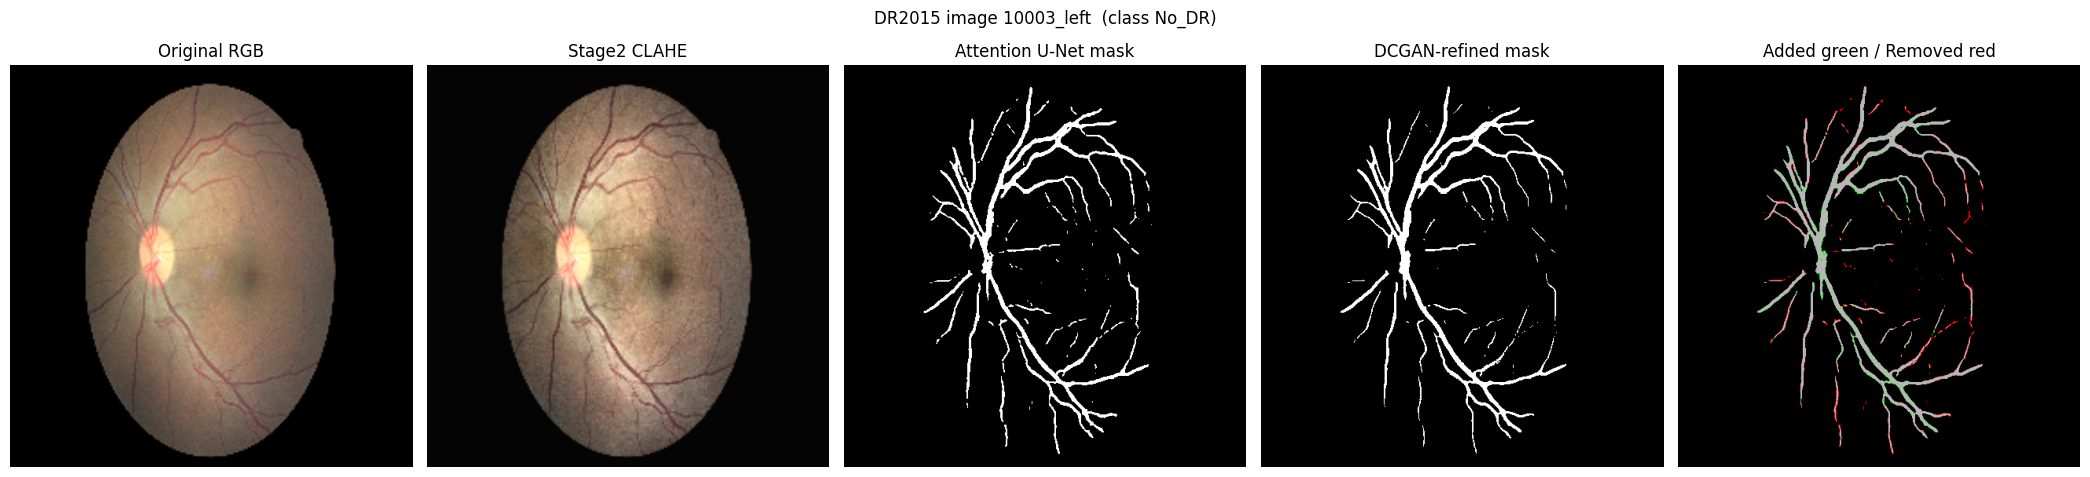

Example image ID: 10003_left
Added: 741 Removed: 1490 Changed: 2231
Saved preview: /content/DR2015_DCGAN_Refined/dr2015_example_refinement.png


In [ ]:
# CELL 5 - REVIEW ONE DR2015 EXAMPLE AND CHANGE MAP
if len(result):
    example=result.iloc[0]
    orig=np.asarray(Image.open(example['img_path']).convert('RGB').resize((SIZE,SIZE)))
    clahe=(stage2_rgb(example['img_path']).permute(1,2,0).numpy()*255).astype('uint8')
    old=np.asarray(Image.open(example['stage2_mask_path']).convert('L'))>127
    new=np.asarray(Image.open(example['stage3_mask_path']).convert('L'))>127
    added=new & ~old
    removed=old & ~new
    overlay=np.zeros((SIZE,SIZE,3),dtype=np.float32)
    overlay[old & new]=[.72,.72,.72]
    overlay[added]=[0,1,0]
    overlay[removed]=[1,0,0]
    fig,ax=plt.subplots(1,5,figsize=(21,5))
    for a,img,title in zip(ax,[orig,clahe,old,new,overlay],
         ['Original RGB','Stage2 CLAHE','Attention U-Net mask','DCGAN-refined mask','Added green / Removed red']):
        a.imshow(img,cmap='gray' if img.ndim==2 else None)
        a.set_title(title)
        a.axis('off')
    fig.suptitle('DR2015 image '+str(example['image_id'])+'  (class '+str(example['class_name'])+')')
    plt.tight_layout()
    preview=EXPORT_DIR/'dr2015_example_refinement.png'
    plt.savefig(preview,dpi=160,bbox_inches='tight')
    plt.show()
    print('Example image ID:',example['image_id'])
    print('Added:',int(added.sum()),'Removed:',int(removed.sum()),
          'Changed:',int((added|removed).sum()))
    print('Saved preview:',preview)


In [ ]:

# ============================================================
# CELL 6 - ZIP AND DOWNLOAD ALL REFINED DR2015 OUTPUTS
# ============================================================

import shutil
from pathlib import Path
from google.colab import files

# Local output folder
EXPORT_DIR = Path("/content/DR2015_DCGAN_Refined")

REFINED_DIR = EXPORT_DIR / "stage3_masks"

# ============================================================
# VERIFY REFINED MASKS
# ============================================================

if not REFINED_DIR.is_dir():
    raise FileNotFoundError(
        "Refined mask folder not found. Run Cell 4 first."
    )

classes = [
    "No_DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferate_DR"
]

total = 0

print("REFINED DR2015 MASK COUNTS")
print("=" * 40)

for cls in classes:

    class_folder = REFINED_DIR / cls

    masks = list(class_folder.glob("*_s3.png"))

    print(f"{cls}: {len(masks)}")

    total += len(masks)

print("=" * 40)
print("Total refined masks:", total)

if total == 0:
    raise RuntimeError(
        "No refined masks found. Run refinement first."
    )

if "df_input" in globals():
    expected = len(df_input)

    if total != expected:
        raise RuntimeError(
            f"Expected {expected} masks, found {total}. "
            "Complete refinement before downloading."
        )

# ============================================================
# CREATE ZIP OF COMPLETE OUTPUT FOLDER
# ============================================================

ZIP_BASE = Path("/content/DR2015_DCGAN_Refined")

print("\nCreating ZIP file...")

zip_path = shutil.make_archive(
    base_name=str(ZIP_BASE),
    format="zip",
    root_dir=str(EXPORT_DIR.parent),
    base_dir=EXPORT_DIR.name
)

print("\nZIP created successfully.")
print("ZIP location:", zip_path)

zip_size_gb = (
    Path(zip_path).stat().st_size / (1024 ** 3)
)

print(f"ZIP size: {zip_size_gb:.3f} GB")

# ============================================================
# DOWNLOAD ZIP TO COMPUTER
# ============================================================

print("\nStarting ZIP download...")

files.download(zip_path)


REFINED DR2015 MASK COUNTS
No_DR: 25810
Mild: 2443
Moderate: 5292
Severe: 873
Proliferate_DR: 708
Total refined masks: 35126

Creating ZIP file...

ZIP created successfully.
ZIP location: /content/DR2015_DCGAN_Refined.zip
ZIP size: 0.467 GB

Starting ZIP download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>